# 쓰레기 이미지 분류 — 제1회 빅데이터 프로그래밍 해커톤

**데이터셋**: [Kaggle Garbage Classification](https://www.kaggle.com/datasets/mostafaabla/garbage-classification) (12클래스, 약 15,500장)
**사용 도구**: PyTorch · torchvision · matplotlib · numpy · pandas (수업 8~10주차 범위)

> 실행 전: 메뉴 **런타임 → 런타임 유형 변경 → T4 GPU** 로 바꾸세요.




## 0. 환경 설정
시드를 고정하고(재현성), device를 정하고, 결과를 저장할 Google Drive 폴더를 만듭니다.

In [24]:
import os, json, glob, time, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
import matplotlib.pyplot as plt

# 재현성 — 매번 같은 결과가 나오도록 시드 고정
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# 장치 — GPU가 있으면 cuda, 없으면 cpu (4주차)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)
if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("⚠ GPU가 아닙니다. 런타임 → 런타임 유형 변경 → T4 GPU 로 바꾸세요.")

device: cuda
GPU: Tesla T4


In [25]:
# 고정 조건 — "한 번에 하나만 바꾼다" 원칙 (9주차 05_experiment 방식)
IMG_SIZE   = 224
BATCH_SIZE = 64
LR         = 1e-3
EPOCHS     = 10      # 실험 B는 5
NUM_WORKERS = 2

# 분할 비율
TRAIN_RATIO, VAL_RATIO = 0.70, 0.15   # 나머지 0.15가 테스트

In [26]:
# Google Drive 마운트 — 결과(csv, png)를 여기 저장해 세션이 끊겨도 보존
from google.colab import drive
drive.mount("/content/drive")

RESULT_DIR = "/content/drive/MyDrive/garbage_hackathon/results"
os.makedirs(RESULT_DIR, exist_ok=True)
print("결과 저장 폴더:", RESULT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
결과 저장 폴더: /content/drive/MyDrive/garbage_hackathon/results


## 1. 데이터 불러오기와 확인
`kagglehub`로 데이터를 내려받고(공개 데이터셋이라 로그인 불필요), `ImageFolder`로 읽습니다.
3주차에서 배운 대로 **모델보다 데이터 확인이 먼저**입니다: 개수 · 클래스 · 분포 · 샘플 이미지.

In [27]:
import kagglehub

path = kagglehub.dataset_download("mostafaabla/garbage-classification")
print("다운로드 위치:", path)

# 폴더 구조 확인 — 클래스별 폴더 12개가 들어 있는 경로를 찾습니다
for root, dirs, files in os.walk(path):
    if len(dirs) >= 10:
        DATA_DIR = root
        break
print("DATA_DIR:", DATA_DIR)
print("클래스 폴더:", sorted(os.listdir(DATA_DIR)))

Using Colab cache for faster access to the 'garbage-classification' dataset.
다운로드 위치: /kaggle/input/garbage-classification
DATA_DIR: /kaggle/input/garbage-classification/garbage_classification
클래스 폴더: ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']


In [28]:
# 일단 변환 없이 원본 구조만 확인 (개수·클래스 이름)
raw_ds = datasets.ImageFolder(DATA_DIR)
class_names = raw_ds.classes
NUM_CLASSES = len(class_names)

print("전체 이미지 수:", len(raw_ds))
print("클래스 수:", NUM_CLASSES)
print("클래스:", class_names)

전체 이미지 수: 15515
클래스 수: 12
클래스: ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']


,class,count
0,battery,945
1,biological,985
2,brown-glass,607
3,cardboard,891
4,clothes,5325
5,green-glass,629
6,metal,769
7,paper,1050
8,plastic,865
9,shoes,1977


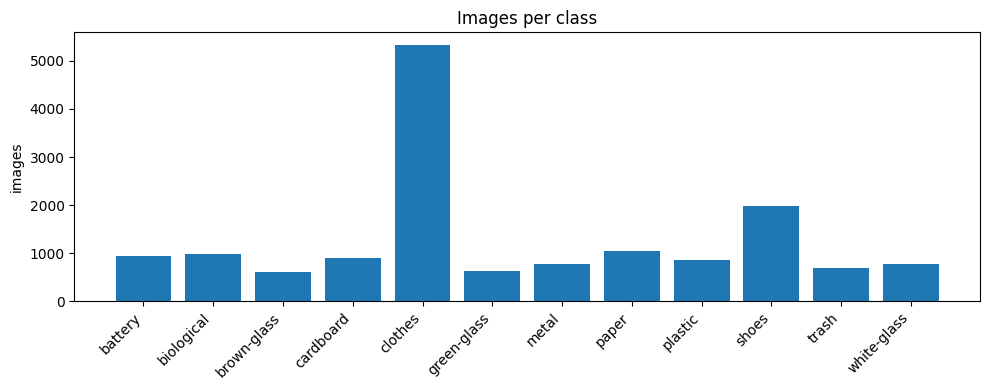

최다: clothes (5325장)
최소: brown-glass (607장)


In [29]:
# 클래스별 개수 — 불균형 확인
counts = pd.Series(raw_ds.targets).value_counts().sort_index()
count_df = pd.DataFrame({"class": class_names, "count": counts.values})
display(count_df)

plt.figure(figsize=(10, 4))
plt.bar(count_df["class"], count_df["count"])
plt.xticks(rotation=45, ha="right")
plt.ylabel("images")
plt.title("Images per class")
plt.tight_layout()
plt.savefig(f"{RESULT_DIR}/01_class_counts.png", dpi=150)
plt.show()

print(f"최다: {count_df.loc[count_df['count'].idxmax(),'class']} ({count_df['count'].max()}장)")
print(f"최소: {count_df.loc[count_df['count'].idxmin(),'class']} ({count_df['count'].min()}장)")

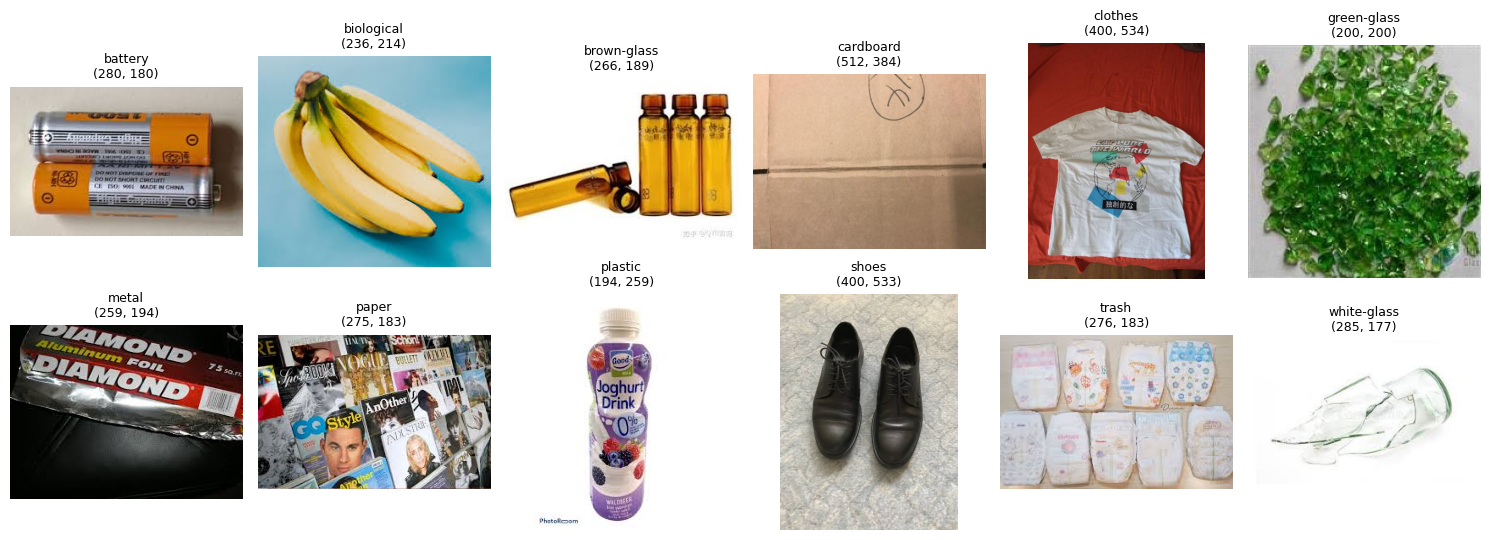

In [30]:
# 샘플 이미지 — 클래스마다 한 장씩
fig, axes = plt.subplots(2, 6, figsize=(15, 5.5))
for ax, c in zip(axes.flat, range(NUM_CLASSES)):
    idx = raw_ds.targets.index(c)          # 그 클래스의 첫 번째 이미지
    img, label = raw_ds[idx]
    ax.imshow(img); ax.set_title(f"{class_names[label]}\n{img.size}", fontsize=9); ax.axis("off")
plt.tight_layout()
plt.savefig(f"{RESULT_DIR}/01_samples.png", dpi=150)
plt.show()

In [31]:
# 이미지 크기 분포 — 크기가 제각각인지 확인 (200장만 표본)
sizes = [raw_ds[i][0].size for i in random.sample(range(len(raw_ds)), 200)]
print("표본 200장 크기 종류 상위 5개:")
print(pd.Series(sizes).value_counts().head())

표본 200장 크기 종류 상위 5개:
(400, 533)    39
(512, 384)    33
(225, 225)    20
(400, 534)    14
(275, 183)    13
Name: count, dtype: int64


## 2. 분할과 변환
- **분할**: 70 / 15 / 15 (학습 / 검증 / 테스트). 테스트셋은 마지막 평가 때 **딱 한 번**만 사용합니다.
- **변환**: 세 종류를 만듭니다.
  - `eval_tf`: Resize + Normalize만 — 검증·테스트용
  - `train_plain_tf`: eval과 같음 — 실험 A의 "증강 없음" 조건
  - `train_aug_tf`: RandomResizedCrop + 좌우반전 + 회전 — 실험 A의 "증강" 조건 (9·10주차)
- Normalize 값은 ImageNet 평균·표준편차 — 실험 C의 사전학습 ResNet18과 맞추기 위해 처음부터 통일합니다.

In [32]:
MEAN = [0.485, 0.456, 0.406]
STD  = [0.229, 0.224, 0.225]

eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

train_plain_tf = eval_tf   # 증강 없음

train_aug_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

In [33]:
# 같은 폴더를 변환만 다르게 세 번 읽습니다 (파일 목록·순서는 동일)
ds_eval  = datasets.ImageFolder(DATA_DIR, transform=eval_tf)
ds_plain = datasets.ImageFolder(DATA_DIR, transform=train_plain_tf)
ds_aug   = datasets.ImageFolder(DATA_DIR, transform=train_aug_tf)

# 인덱스를 한 번 섞어서 세 데이터셋에 똑같이 적용 → 어떤 변환을 쓰든 같은 이미지가 같은 split에 들어감
n = len(ds_eval)
g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(n, generator=g).tolist()

n_train = int(n * TRAIN_RATIO)
n_val   = int(n * VAL_RATIO)
train_idx = perm[:n_train]
val_idx   = perm[n_train:n_train + n_val]
test_idx  = perm[n_train + n_val:]

train_plain_ds = Subset(ds_plain, train_idx)
train_aug_ds   = Subset(ds_aug,   train_idx)
val_ds         = Subset(ds_eval,  val_idx)
test_ds        = Subset(ds_eval,  test_idx)

print(f"학습 {len(train_idx)} / 검증 {len(val_idx)} / 테스트 {len(test_idx)}  (합 {n})")

학습 10860 / 검증 2327 / 테스트 2328  (합 15515)


In [34]:
# 분할 후 클래스 분포가 고르게 들어갔는지 확인
targets = np.array(ds_eval.targets)
split_df = pd.DataFrame({
    "class": class_names,
    "train": np.bincount(targets[train_idx], minlength=NUM_CLASSES),
    "val":   np.bincount(targets[val_idx],   minlength=NUM_CLASSES),
    "test":  np.bincount(targets[test_idx],  minlength=NUM_CLASSES),
})
display(split_df)
split_df.to_csv(f"{RESULT_DIR}/02_split_counts.csv", index=False)

,class,train,val,test
0,battery,638,141,166
1,biological,696,164,125
2,brown-glass,414,98,95
3,cardboard,646,124,121
4,clothes,3682,849,794
5,green-glass,419,91,119
6,metal,538,121,110
7,paper,744,146,160
8,plastic,623,122,120
9,shoes,1388,284,305


In [35]:
def make_loader(ds, shuffle, batch_size=BATCH_SIZE):
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle,
                      num_workers=NUM_WORKERS, pin_memory=(device == "cuda"))

train_plain_loader = make_loader(train_plain_ds, shuffle=True)
train_aug_loader   = make_loader(train_aug_ds,   shuffle=True)
val_loader         = make_loader(val_ds,  shuffle=False)
test_loader        = make_loader(test_ds, shuffle=False)

# 배치 하나 꺼내 shape 확인 (5주차) — (배치, 채널, 높이, 너비)
xb, yb = next(iter(train_aug_loader))
print("입력 batch:", tuple(xb.shape), xb.dtype)
print("정답 batch:", tuple(yb.shape), yb.dtype)
print("한 epoch의 step 수:", len(train_aug_loader))

입력 batch: (64, 3, 224, 224) torch.float32
정답 batch: (64,) torch.int64
한 epoch의 step 수: 170


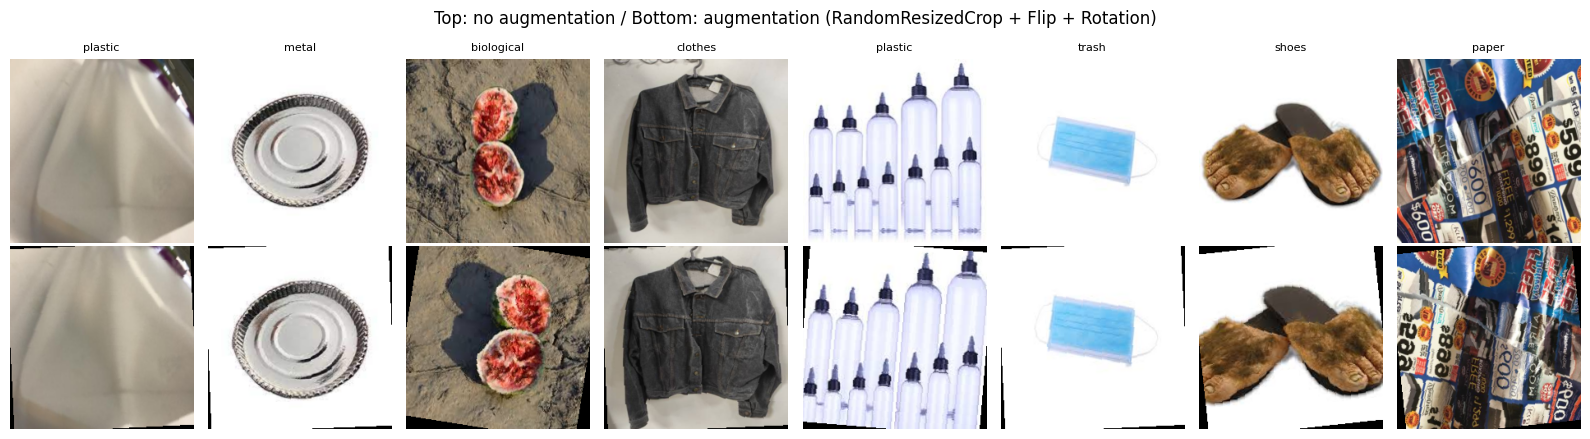

In [36]:
# 증강 전/후 비교 — 같은 이미지 8장을 증강 없이 / 증강 적용해서 나란히
def denorm(x):
    x = x * torch.tensor(STD).view(3,1,1) + torch.tensor(MEAN).view(3,1,1)
    return x.clamp(0, 1).permute(1, 2, 0).numpy()

fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for j in range(8):
    i = train_idx[j]
    axes[0, j].imshow(denorm(ds_plain[i][0])); axes[0, j].set_title(class_names[ds_plain[i][1]], fontsize=8); axes[0, j].axis("off")
    axes[1, j].imshow(denorm(ds_aug[i][0]));   axes[1, j].axis("off")
axes[0, 0].set_ylabel("plain"); axes[1, 0].set_ylabel("aug")
plt.suptitle("Top: no augmentation / Bottom: augmentation (RandomResizedCrop + Flip + Rotation)")
plt.tight_layout()
plt.savefig(f"{RESULT_DIR}/02_augmentation.png", dpi=150)
plt.show()

### 섹션 0~2 확인 체크리스트
- [ ] device가 `cuda`로 나온다
- [ ] 클래스 12개, 전체 이미지 약 15,500장
- [ ] 학습/검증/테스트 개수 합이 전체와 같다
- [ ] 입력 batch shape이 `(64, 3, 224, 224)`, dtype `float32`
- [ ] 증강 그림에서 아래 줄이 위 줄과 달라 보인다
- [ ] Drive의 `garbage_hackathon/results`에 png 3개, csv 1개가 생겼다

여기까지 통과하면 **섹션 3 (실험 A)** 으로 넘어갑니다.

## 3. 실험 A — 과적합과 데이터 증강
9주차 05_experiment와 같은 형식입니다. **한 가지만 바꾸고** 나머지는 모두 같게 둡니다.

| 모델 | 바꾼 것 | 학습 데이터 |
|---|---|---|
| 기본 CNN | — | 증강 없음 |
| Dropout CNN | Dropout 0.5 | 증강 없음 |
| BatchNorm CNN | BatchNorm 추가 | 증강 없음 |
| 데이터 증강 CNN | — | **증강 적용** |

기본 CNN에서 학습 정확도는 오르는데 검증 정확도가 멈추면(학습 − 검증 차이가 벌어지면) **과적합**입니다.
나머지 세 모델이 그 차이를 얼마나 줄이는지 봅니다.

In [23]:
def make_cnn(dropout=0.0, batchnorm=False, n_classes=NUM_CLASSES):
    """8·9주차 CNN 구조. 224px 컬러 입력에 맞춰 conv 블록을 4개로 늘리고,
    마지막에 AdaptiveAvgPool2d(1)을 넣어 입력 크기와 무관하게 Flatten 크기가 고정되도록 했습니다."""
    def conv_block(cin, cout):
        layers = [nn.Conv2d(cin, cout, 3, padding=1)]
        if batchnorm:
            layers.append(nn.BatchNorm2d(cout))
        layers += [nn.ReLU(), nn.MaxPool2d(2)]
        return layers

    head = [nn.AdaptiveAvgPool2d(1), nn.Flatten()]     # (배치, 128, 1, 1) → (배치, 128)
    if dropout:
        head.append(nn.Dropout(dropout))
    head += [nn.Linear(128, 256)]
    if batchnorm:
        head.append(nn.BatchNorm1d(256))
    head.append(nn.ReLU())
    if dropout:
        head.append(nn.Dropout(dropout))
    head.append(nn.Linear(256, n_classes))

    return nn.Sequential(
        *conv_block(3, 16),    # 224 → 112
        *conv_block(16, 32),   # 112 → 56
        *conv_block(32, 64),   # 56 → 28
        *conv_block(64, 128),  # 28 → 14
        *head,
    )

# 모양 확인 (8주차) — 배치 하나를 넣어 출력 shape이 (배치, 12)인지
m = make_cnn()
out = m(torch.zeros(2, 3, IMG_SIZE, IMG_SIZE))
print("출력 shape:", tuple(out.shape))
print(f"파라미터 {sum(p.numel() for p in m.parameters()):,}개")

출력 shape: (2, 12)
파라미터 133,548개


In [ ]:
loss_fn = nn.CrossEntropyLoss()

def measure(model, loader):
    """손실과 정확도 측정 — eval 모드, 미분 없이 (5주차)"""
    model.eval()
    loss_sum = correct = total = 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss_sum += loss_fn(out, y).item() * y.numel()
            correct += (out.argmax(dim=1) == y).sum().item()
            total += y.numel()
    return loss_sum / total, correct / total


def train_model(model, train_loader, epochs=EPOCHS, lr=LR, tag=""):
    """다섯 단계 학습 루프 (5주차). 매 epoch 끝에 학습/검증 손실·정확도를 기록합니다.
    hist 한 줄 = (train_loss, train_acc, val_loss, val_acc)"""
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = []
    start = time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        loss_sum = correct = total = 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = loss_fn(out, y)
            opt.zero_grad(); loss.backward(); opt.step()
            loss_sum += loss.item() * y.numel()
            correct += (out.argmax(dim=1) == y).sum().item()
            total += y.numel()
        train_loss, train_acc = loss_sum / total, correct / total   # 학습 중 집계 (재측정 시간 절약)
        val_loss, val_acc = measure(model, val_loader)
        hist.append((train_loss, train_acc, val_loss, val_acc))
        print(f"  [{tag}] epoch {epoch:2d}/{epochs}  학습 {train_acc:.4f}  검증 {val_acc:.4f}  "
              f"검증손실 {val_loss:.4f}  ({time.time()-start:.0f}초)")
    return hist, time.time() - start

In [ ]:
configs_A = [
    ("기본 CNN",        dict(dropout=0.0, batchnorm=False), train_plain_loader),
    ("Dropout CNN",     dict(dropout=0.5, batchnorm=False), train_plain_loader),
    ("BatchNorm CNN",   dict(dropout=0.0, batchnorm=True),  train_plain_loader),
    ("데이터 증강 CNN",  dict(dropout=0.0, batchnorm=False), train_aug_loader),
]

results_A = {}
for name, kw, loader in configs_A:
    print(f"\n▶ {name}")
    torch.manual_seed(SEED)                      # 모든 모델이 같은 초기 가중치에서 출발
    model = make_cnn(**kw).to(device)
    hist, elapsed = train_model(model, loader, tag=name)
    results_A[name] = {"model": model, "hist": hist, "time": elapsed}
    print(f"  학습 시간 {elapsed/60:.1f}분")

    # epoch별 기록을 Drive에 즉시 저장 (세션이 끊겨도 보존)
    pd.DataFrame(hist, columns=["train_loss","train_acc","val_loss","val_acc"]).to_csv(
        f"{RESULT_DIR}/03A_hist_{name}.csv", index_label="epoch")


▶ 기본 CNN
  [기본 CNN] epoch  1/10  학습 0.3921  검증 0.4886  검증손실 1.5192  (81초)
  [기본 CNN] epoch  2/10  학습 0.5299  검증 0.5866  검증손실 1.2344  (132초)
  [기본 CNN] epoch  3/10  학습 0.5715  검증 0.5883  검증손실 1.1749  (183초)
  [기본 CNN] epoch  4/10  학습 0.6001  검증 0.6021  검증손실 1.1261  (235초)
  [기본 CNN] epoch  5/10  학습 0.6183  검증 0.6124  검증손실 1.1276  (285초)
  [기본 CNN] epoch  6/10  학습 0.6356  검증 0.6339  검증손실 1.0525  (337초)
  [기본 CNN] epoch  7/10  학습 0.6466  검증 0.6575  검증손실 1.0011  (388초)
  [기본 CNN] epoch  8/10  학습 0.6603  검증 0.6837  검증손실 0.9582  (443초)
  [기본 CNN] epoch  9/10  학습 0.6734  검증 0.6768  검증손실 0.9486  (498초)
  [기본 CNN] epoch 10/10  학습 0.6858  검증 0.7000  검증손실 0.8938  (554초)
  학습 시간 9.2분

▶ Dropout CNN
  [Dropout CNN] epoch  1/10  학습 0.3677  검증 0.4555  검증손실 1.6569  (54초)
  [Dropout CNN] epoch  2/10  학습 0.4564  검증 0.5264  검증손실 1.4271  (110초)
  [Dropout CNN] epoch  3/10  학습 0.4907  검증 0.5578  검증손실 1.3482  (165초)
  [Dropout CNN] epoch  4/10  학습 0.5216  검증 0.5733  검증손실 1.2853  (218초)
  [Dropout CNN] epoc

### 3-1. 결과 비교표

In [ ]:
rows = []
for name in results_A:
    h = results_A[name]["hist"]
    rows.append({
        "모델": name,
        "학습 정확도": round(h[-1][1], 4),
        "검증 정확도": round(h[-1][3], 4),
        "차이(과적합)": round(h[-1][1] - h[-1][3], 4),
        "최고 검증": round(max(x[3] for x in h), 4),
        "검증 손실": round(h[-1][2], 4),
        "학습 시간(분)": round(results_A[name]["time"] / 60, 1),
    })
table_A = pd.DataFrame(rows)
display(table_A)
table_A.to_csv(f"{RESULT_DIR}/03A_table.csv", index=False)

best_A = table_A.loc[table_A["검증 정확도"].idxmax(), "모델"]
print(f"\n검증 정확도가 가장 높은 모델: {best_A}")

,모델,학습 정확도,검증 정확도,차이(과적합),최고 검증,검증 손실,학습 시간(분)
0,기본 CNN,0.6858,0.7000,-0.0142,0.7000,0.8938,9.2
1,Dropout CNN,0.5943,0.6498,-0.0555,0.6498,1.0876,8.9
2,BatchNorm CNN,0.7964,0.7331,0.0633,0.7336,0.8041,9.0
3,데이터 증강 CNN,0.6720,0.6541,0.0179,0.6566,0.9939,9.8



검증 정확도가 가장 높은 모델: BatchNorm CNN


### 3-2. 학습 곡선 — 네 모델 겹쳐 보기
- **학습 손실**은 모두 내려가는데 **검증 손실**이 다시 올라가면 과적합
- **학습 − 검증 차이**가 작을수록 일반화가 잘 된 모델

/tmp/ipykernel_402/2008952070.py:13: UserWarning: Glyph 44592 (\N{HANGUL SYLLABLE GI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_402/2008952070.py:13: UserWarning: Glyph 48376 (\N{HANGUL SYLLABLE BON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_402/2008952070.py:13: UserWarning: Glyph 45936 (\N{HANGUL SYLLABLE DE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_402/2008952070.py:13: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_402/2008952070.py:13: UserWarning: Glyph 53552 (\N{HANGUL SYLLABLE TEO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_402/2008952070.py:13: UserWarning: Glyph 51613 (\N{HANGUL SYLLABLE JEUNG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_402/2008952070.py:13: UserWarning: Glyph 44053 (\N{HANGUL SYLLABLE GANG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


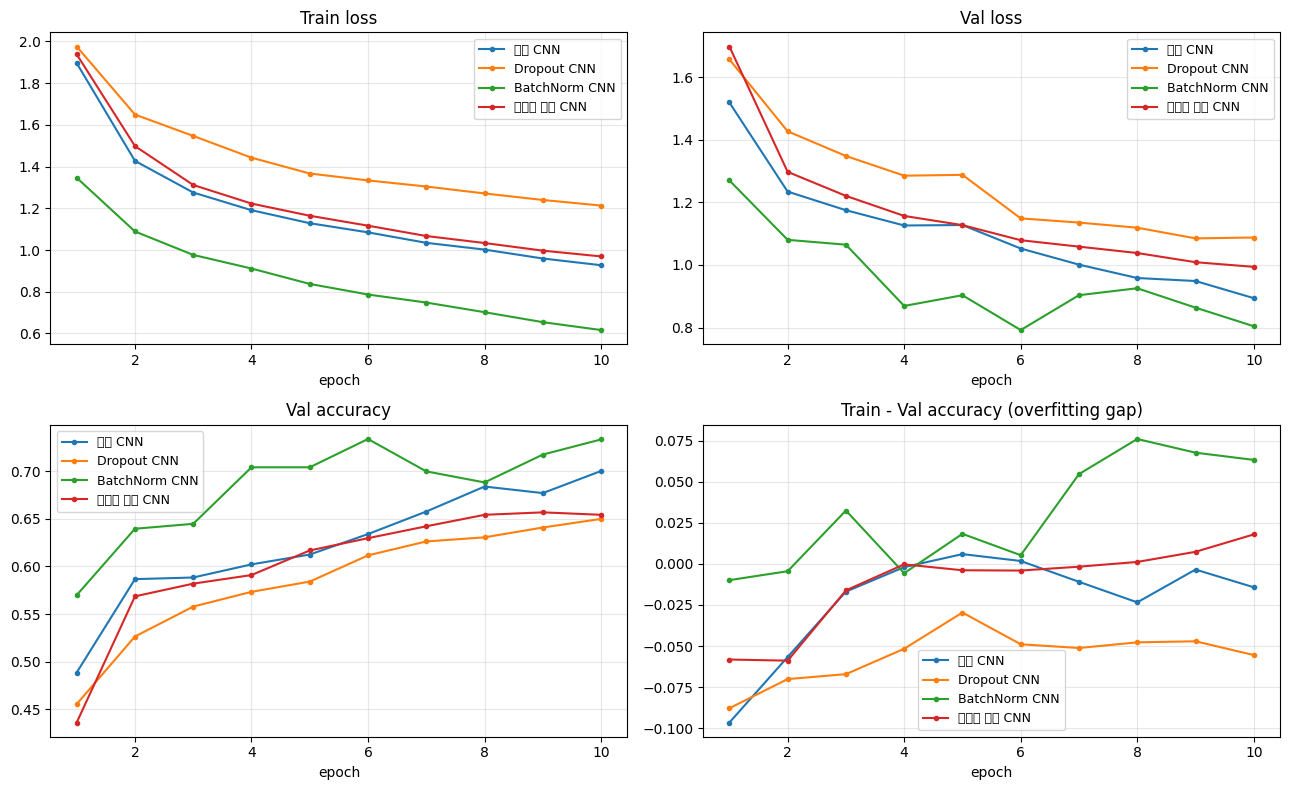

In [ ]:
xs = range(1, EPOCHS + 1)
fig, ax = plt.subplots(2, 2, figsize=(13, 8))
for name in results_A:
    h = results_A[name]["hist"]
    ax[0,0].plot(xs, [v[0] for v in h], marker="o", ms=3, label=name)
    ax[0,1].plot(xs, [v[2] for v in h], marker="o", ms=3, label=name)
    ax[1,0].plot(xs, [v[3] for v in h], marker="o", ms=3, label=name)
    ax[1,1].plot(xs, [v[1]-v[3] for v in h], marker="o", ms=3, label=name)

titles = ["Train loss", "Val loss", "Val accuracy", "Train - Val accuracy (overfitting gap)"]
for a, t in zip(ax.flatten(), titles):
    a.set_title(t); a.set_xlabel("epoch"); a.legend(fontsize=9); a.grid(alpha=.3)
plt.tight_layout()
plt.savefig(f"{RESULT_DIR}/03A_curves.png", dpi=150)
plt.show()

### 3-3. 가장 좋은 모델의 클래스별 검증 정확도
어느 클래스가 어려운지 봅니다. (테스트셋은 아직 쓰지 않습니다 — 섹션 6에서 한 번만)

,클래스,기본 CNN,Dropout CNN,BatchNorm CNN,데이터 증강 CNN
0,battery,0.447,0.702,0.652,0.284
1,biological,0.628,0.610,0.634,0.591
2,brown-glass,0.673,0.551,0.684,0.612
3,cardboard,0.750,0.621,0.694,0.702
4,clothes,0.920,0.902,0.846,0.899
5,green-glass,0.802,0.813,0.791,0.791
6,metal,0.388,0.207,0.777,0.347
7,paper,0.753,0.760,0.788,0.630
8,plastic,0.385,0.459,0.557,0.352
9,shoes,0.507,0.215,0.567,0.437


/tmp/ipykernel_402/3235895088.py:21: UserWarning: Glyph 53364 (\N{HANGUL SYLLABLE KEUL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_402/3235895088.py:21: UserWarning: Glyph 47000 (\N{HANGUL SYLLABLE RAE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_402/3235895088.py:21: UserWarning: Glyph 49828 (\N{HANGUL SYLLABLE SEU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_402/3235895088.py:21: UserWarning: Glyph 44592 (\N{HANGUL SYLLABLE GI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_402/3235895088.py:21: UserWarning: Glyph 48376 (\N{HANGUL SYLLABLE BON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_402/3235895088.py:21: UserWarning: Glyph 45936 (\N{HANGUL SYLLABLE DE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_402/3235895088.py:21: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/t

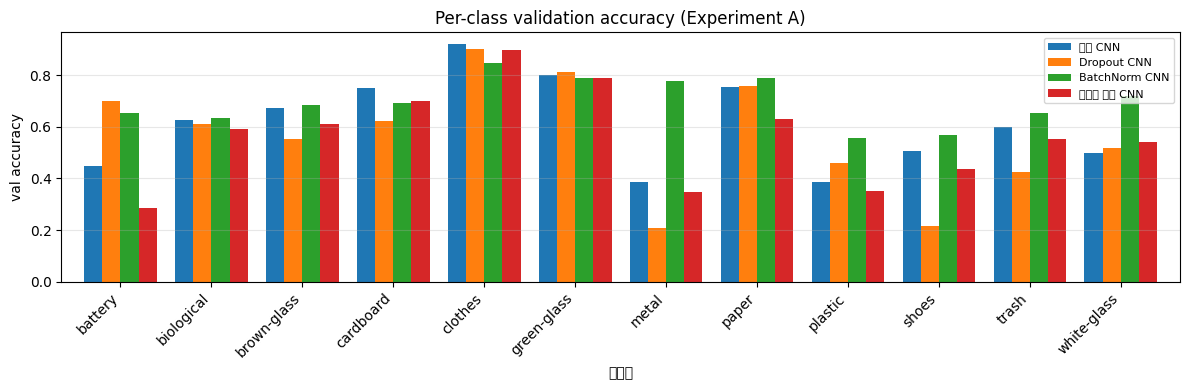

In [ ]:
def per_class_acc(model, loader):
    model.eval()
    correct = torch.zeros(NUM_CLASSES); total = torch.zeros(NUM_CLASSES)
    with torch.no_grad():
        for x, y in loader:
            p = model(x.to(device)).argmax(dim=1).cpu()
            for c in range(NUM_CLASSES):
                mask = y == c
                total[c] += mask.sum(); correct[c] += (p[mask] == c).sum()
    return (correct / total).tolist()

cls_A = pd.DataFrame({"클래스": class_names})
for name in results_A:
    cls_A[name] = [round(v, 3) for v in per_class_acc(results_A[name]["model"], val_loader)]
display(cls_A)
cls_A.to_csv(f"{RESULT_DIR}/03A_per_class.csv", index=False)

cls_A.set_index("클래스").plot.bar(figsize=(12, 4), width=0.8)
plt.ylabel("val accuracy"); plt.title("Per-class validation accuracy (Experiment A)")
plt.xticks(rotation=45, ha="right"); plt.legend(fontsize=8); plt.grid(axis="y", alpha=.3)
plt.tight_layout()
plt.savefig(f"{RESULT_DIR}/03A_per_class.png", dpi=150)
plt.show()

### 3-4. 가장 좋은 모델의 틀린 사례 (검증셋)

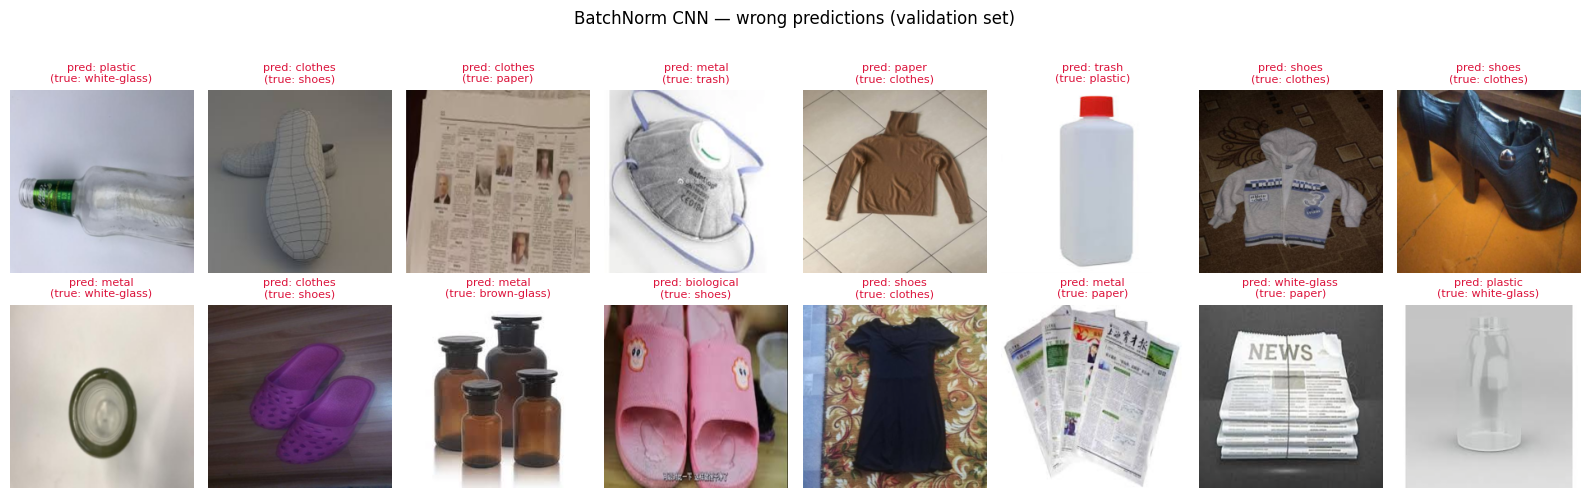

In [ ]:
model = results_A[best_A]["model"]; model.eval()
imgs, trues, preds = [], [], []
with torch.no_grad():
    for x, y in val_loader:
        p = model(x.to(device)).argmax(dim=1).cpu()
        wrong = p != y
        if wrong.any():
            imgs.append(x[wrong]); trues.append(y[wrong]); preds.append(p[wrong])
        if sum(len(t) for t in trues) >= 16:
            break
imgs = torch.cat(imgs)[:16]; trues = torch.cat(trues)[:16]; preds = torch.cat(preds)[:16]

fig, axes = plt.subplots(2, 8, figsize=(16, 5))
for ax_, i in zip(axes.flatten(), range(len(imgs))):
    ax_.imshow(denorm(imgs[i]))
    ax_.set_title(f"pred: {class_names[preds[i]]}\n(true: {class_names[trues[i]]})", fontsize=8, color="crimson")
    ax_.axis("off")
plt.suptitle(f"{best_A} — wrong predictions (validation set)", y=1.02)
plt.tight_layout()
plt.savefig(f"{RESULT_DIR}/03A_wrong.png", dpi=150)
plt.show()

In [ ]:
# 실험 A 최고 모델 가중치 저장 — 실험 B의 출발점이자 세션 끊김 대비
torch.save(results_A[best_A]["model"].state_dict(), f"{RESULT_DIR}/03A_best_{best_A}.pt")
print("저장:", f"{RESULT_DIR}/03A_best_{best_A}.pt")

저장: /content/drive/MyDrive/garbage_hackathon/results/03A_best_BatchNorm CNN.pt


### 실험 A 확인 체크리스트
- [ ] 4개 모델 모두 10 epoch 학습 완료 (모델당 약 8~12분 예상)
- [ ] 비교표에서 기본 CNN의 "차이(과적합)"가 다른 세 모델보다 큰가 → 과적합 근거
- [ ] 학습 곡선 그림에서 기본 CNN의 검증 손실이 뒤로 갈수록 올라가는가
- [ ] Drive `results/`에 `03A_*.csv` 6개, `03A_*.png` 3개, `.pt` 1개가 생겼다

→ 결과 숫자(비교표)를 알려주시면 **섹션 4 실험 B**에서 어느 모델을 고정할지 정합니다.

### 3-5. 과적합 확인 추가 실험 — 20 epoch

**왜 추가했나**: 10 epoch 결과에서 네 모델 모두 검증 정확도가 아직 오르는 중이었고, 학습−검증 차이도 거의 없었습니다(기본 CNN +0.001).
즉 과적합이 나타나기 **전에** 학습이 끝난 상태라, "과적합 발생 → 대응 → 완화"를 곡선으로 보여주기 위해 epoch을 20으로 늘려 두 모델을 다시 학습합니다.

| 모델 | 구성 | 기대 |
|---|---|---|
| BatchNorm CNN (20ep) | 실험 A 최고 모델 그대로 | epoch이 늘면 학습−검증 차이가 **벌어짐** (과적합 발생) |
| BatchNorm + Dropout 0.3 + 증강 (20ep) | 9주차 결론처럼 세 기법 **조합** | 차이가 **줄어듦** (과적합 완화) |

Dropout은 실험 A에서 0.5가 학습을 방해했으므로 0.3으로 낮췄습니다. 다른 조건(224px, batch 64, lr 1e-3, Adam, 시드)은 모두 동일합니다.
예상 시간: 모델당 약 20분, 합계 40분. 결과 csv가 이미 Drive에 있으면 학습을 건너뛰고 불러옵니다.

In [ ]:
EPOCHS_LONG = 20

configs_35 = [
    ("BatchNorm CNN (20ep)",              dict(dropout=0.0, batchnorm=True), train_plain_loader),
    ("BatchNorm+Dropout0.3+증강 (20ep)",   dict(dropout=0.3, batchnorm=True), train_aug_loader),
]

results_35 = {}
for name, kw, loader in configs_35:
    hist_path = f"{RESULT_DIR}/035_hist_{name}.csv"
    if os.path.exists(hist_path):                       # 이미 돌린 적이 있으면 불러오기만
        h = pd.read_csv(hist_path, index_col="epoch")
        results_35[name] = {"model": None, "hist": list(h.itertuples(index=False, name=None)), "time": float(h.attrs.get("time", 0))}
        print(f"▶ {name}: 저장된 결과 불러옴 ({hist_path})")
        continue

    print(f"\n▶ {name}")
    torch.manual_seed(SEED)
    model = make_cnn(**kw).to(device)
    hist, elapsed = train_model(model, loader, epochs=EPOCHS_LONG, tag=name)
    results_35[name] = {"model": model, "hist": hist, "time": elapsed}
    print(f"  학습 시간 {elapsed/60:.1f}분")
    pd.DataFrame(hist, columns=["train_loss","train_acc","val_loss","val_acc"]).to_csv(hist_path, index_label="epoch")
    torch.save(model.state_dict(), f"{RESULT_DIR}/035_{name}.pt")

▶ BatchNorm CNN (20ep): 저장된 결과 불러옴 (/content/drive/MyDrive/garbage_hackathon/results/035_hist_BatchNorm CNN (20ep).csv)
▶ BatchNorm+Dropout0.3+증강 (20ep): 저장된 결과 불러옴 (/content/drive/MyDrive/garbage_hackathon/results/035_hist_BatchNorm+Dropout0.3+증강 (20ep).csv)


#### 3-5-1. 비교표 — 10 epoch 시점과 20 epoch 시점을 나란히
같은 모델이 epoch 10과 20에서 학습−검증 차이가 어떻게 달라지는지, 그리고 조합 모델에서 그 차이가 얼마나 줄어드는지를 봅니다.

In [ ]:
rows = []
for name, r in results_35.items():
    h = r["hist"]
    for ep in (10, 20):
        v = h[ep-1]
        rows.append({"모델": name, "epoch": ep,
                     "학습 정확도": round(v[1], 4), "검증 정확도": round(v[3], 4),
                     "차이(과적합)": round(v[1]-v[3], 4),
                     "학습 손실": round(v[0], 4), "검증 손실": round(v[2], 4)})
    rows[-1]["최고 검증"] = round(max(x[3] for x in h), 4)
    rows[-1]["최고 검증 epoch"] = max(range(len(h)), key=lambda i: h[i][3]) + 1
table_35 = pd.DataFrame(rows)
display(table_35)
table_35.to_csv(f"{RESULT_DIR}/035_table.csv", index=False)

,모델,epoch,학습 정확도,검증 정확도,차이(과적합),학습 손실,검증 손실,최고 검증,최고 검증 epoch
0,BatchNorm CNN (20ep),10,0.7978,0.7486,0.0492,0.6050,0.7812,NaN,NaN
1,BatchNorm CNN (20ep),20,0.8738,0.7422,0.1316,0.3795,0.8697,0.7937,19.0
2,BatchNorm+Dropout0.3+증강 (20ep),10,0.6685,0.6691,-0.0006,0.9920,0.9985,NaN,NaN
3,BatchNorm+Dropout0.3+증강 (20ep),20,0.7208,0.6988,0.0221,0.8365,0.8722,0.7452,16.0


#### 3-5-2. 학습 곡선 — 과적합이 보이는 자리
왼쪽 위: 검증 손실이 **다시 올라가기 시작하는 지점**이 과적합 시작점입니다. 오른쪽 아래: 학습−검증 차이가 벌어지는 폭을 두 모델에서 비교합니다.

/tmp/ipykernel_402/2756443671.py:18: UserWarning: Glyph 51613 (\N{HANGUL SYLLABLE JEUNG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_402/2756443671.py:18: UserWarning: Glyph 44053 (\N{HANGUL SYLLABLE GANG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_402/2756443671.py:19: UserWarning: Glyph 51613 (\N{HANGUL SYLLABLE JEUNG}) missing from font(s) DejaVu Sans.
  plt.savefig(f"{RESULT_DIR}/035_curves.png", dpi=150)
/tmp/ipykernel_402/2756443671.py:19: UserWarning: Glyph 44053 (\N{HANGUL SYLLABLE GANG}) missing from font(s) DejaVu Sans.
  plt.savefig(f"{RESULT_DIR}/035_curves.png", dpi=150)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51613 (\N{HANGUL SYLLABLE JEUNG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44053 (\N{HANGUL SYLLABLE GANG}) missing from font(s) DejaVu S

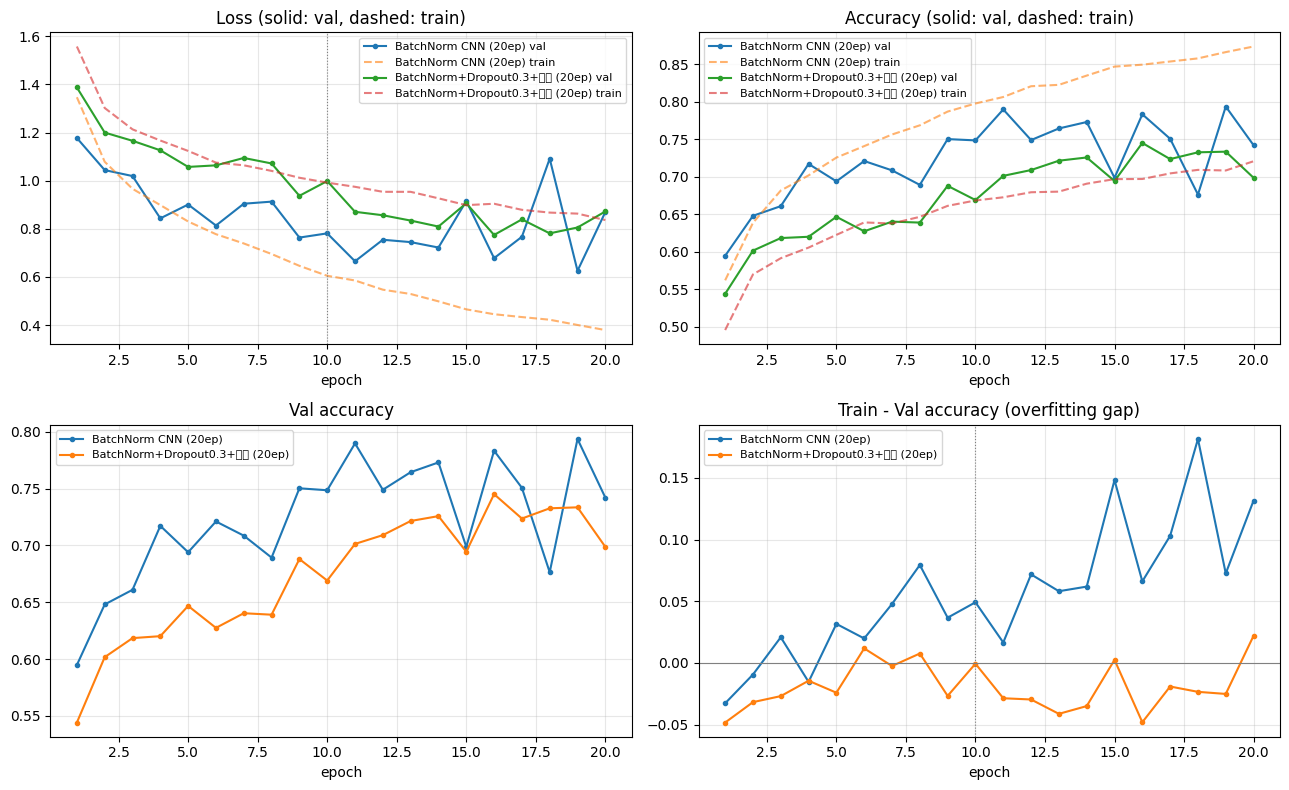

BatchNorm CNN (20ep): 검증 정확도 최고 epoch = 19, 이후 1 epoch 동안 하락/정체 → 최종 차이 +0.1316
BatchNorm+Dropout0.3+증강 (20ep): 검증 정확도 최고 epoch = 16, 이후 4 epoch 동안 하락/정체 → 최종 차이 +0.0221


In [ ]:
xs = range(1, EPOCHS_LONG + 1)
fig, ax = plt.subplots(2, 2, figsize=(13, 8))
for name, r in results_35.items():
    h = r["hist"]
    ax[0,0].plot(xs, [v[2] for v in h], marker="o", ms=3, label=f"{name} val")
    ax[0,0].plot(xs, [v[0] for v in h], ls="--", alpha=.6, label=f"{name} train")
    ax[0,1].plot(xs, [v[3] for v in h], marker="o", ms=3, label=f"{name} val")
    ax[0,1].plot(xs, [v[1] for v in h], ls="--", alpha=.6, label=f"{name} train")
    ax[1,0].plot(xs, [v[3] for v in h], marker="o", ms=3, label=name)
    ax[1,1].plot(xs, [v[1]-v[3] for v in h], marker="o", ms=3, label=name)
ax[1,1].axhline(0, color="gray", lw=.8)
ax[0,0].axvline(10, color="gray", ls=":", lw=.8); ax[1,1].axvline(10, color="gray", ls=":", lw=.8)

titles = ["Loss (solid: val, dashed: train)", "Accuracy (solid: val, dashed: train)",
          "Val accuracy", "Train - Val accuracy (overfitting gap)"]
for a, t in zip(ax.flatten(), titles):
    a.set_title(t); a.set_xlabel("epoch"); a.legend(fontsize=8); a.grid(alpha=.3)
plt.tight_layout()
plt.savefig(f"{RESULT_DIR}/035_curves.png", dpi=150)
plt.show()

for name, r in results_35.items():
    h = r["hist"]
    best_ep = max(range(len(h)), key=lambda i: h[i][3]) + 1
    print(f"{name}: 검증 정확도 최고 epoch = {best_ep}, 이후 {EPOCHS_LONG-best_ep} epoch 동안 하락/정체 → "
          f"최종 차이 {h[-1][1]-h[-1][3]:+.4f}")

## 4. 실험 B — 하이퍼파라미터 튜닝

**기준 모델**: 실험 A에서 검증 정확도가 가장 높았던 **BatchNorm CNN**
**원칙**: 한 번에 **하나만** 바꾸고 나머지는 기준값 유지 (9주차 05_experiment 방식)
**epoch**: 5 (경향 비교 목적, 시간 절약) · 표에는 **최종 검증**과 **최고 검증**을 함께 기록해 짧은 epoch의 출렁임을 보완

| 항목 | 후보 | 기준값 | 비교 이유 |
|---|---|---|---|
| ① 학습률 | 1e-2 / 1e-3 / 1e-4 | 1e-3 | 3-5에서 검증 정확도가 크게 출렁임 → 학습률이 높은지 확인 |
| ② 배치 크기 | 32 / 64 / 128 | 64 | 배치가 작으면 step이 많아 더 자주 갱신, 크면 안정적이지만 느리게 배움 |
| ③ Dropout | 0 / 0.3 / 0.5 | 0 | BatchNorm과 함께 쓸 때 적정 Dropout 값 |

기준값 조합(lr 1e-3, batch 64, dropout 0)은 세 항목에 공통이므로 한 번만 학습 → 총 **7회 × 5 epoch ≈ 30분**.
이미 학습한 설정은 csv에서 불러오므로 중간에 끊겨도 처음부터 다시 돌지 않습니다.


In [ ]:
import json

EPOCHS_B = 5
BASE = dict(lr=LR, batch=BATCH_SIZE, dropout=0.0)      # 기준값

# 한 번에 하나만 바꾼 설정 목록 (기준 조합은 중복이므로 1회만)
configs_B = {"기준 (lr 1e-3, batch 64, dropout 0)": dict(BASE)}
for lr in (1e-2, 1e-4):
    configs_B[f"lr={lr:g}"] = dict(BASE, lr=lr)
for b in (32, 128):
    configs_B[f"batch={b}"] = dict(BASE, batch=b)
for d in (0.3, 0.5):
    configs_B[f"dropout={d}"] = dict(BASE, dropout=d)

loaders_B = {}      # 배치 크기별 DataLoader 재사용
def get_loader(batch):
    if batch not in loaders_B:
        loaders_B[batch] = make_loader(train_plain_ds, shuffle=True, batch_size=batch)
    return loaders_B[batch]

results_B = {}
for name, cfg in configs_B.items():
    hist_path = f"{RESULT_DIR}/04B_hist_{name}.csv"
    if os.path.exists(hist_path):
        h = pd.read_csv(hist_path, index_col="epoch")
        results_B[name] = {"cfg": cfg, "hist": list(h[["train_loss","train_acc","val_loss","val_acc"]].itertuples(index=False, name=None)),
                           "time": float(h["time_min"].iloc[0]) * 60}
        print(f"▶ {name}: 저장된 결과 불러옴")
        continue

    print(f"\n▶ {name}   {cfg}")
    torch.manual_seed(SEED)
    model = make_cnn(dropout=cfg["dropout"], batchnorm=True).to(device)
    hist, elapsed = train_model(model, get_loader(cfg["batch"]), epochs=EPOCHS_B, lr=cfg["lr"], tag=name)
    results_B[name] = {"cfg": cfg, "hist": hist, "time": elapsed}
    print(f"  학습 시간 {elapsed/60:.1f}분")
    df = pd.DataFrame(hist, columns=["train_loss","train_acc","val_loss","val_acc"])
    df["time_min"] = round(elapsed / 60, 2)
    df.to_csv(hist_path, index_label="epoch")
    del model; torch.cuda.empty_cache()


▶ 기준 (lr 1e-3, batch 64, dropout 0): 저장된 결과 불러옴
▶ lr=0.01: 저장된 결과 불러옴
▶ lr=0.0001: 저장된 결과 불러옴
▶ batch=32: 저장된 결과 불러옴
▶ batch=128: 저장된 결과 불러옴
▶ dropout=0.3: 저장된 결과 불러옴
▶ dropout=0.5: 저장된 결과 불러옴


### 4-1. 항목별 비교표
세 항목 각각에 대해 기준값 행을 포함해 3행씩 보여줍니다. **최고 검증**이 가장 높은 값을 그 항목의 최적값으로 고릅니다.


In [ ]:
def summarize(name):
    r = results_B[name]; h = r["hist"]
    return {"설정": name, "lr": r["cfg"]["lr"], "batch": r["cfg"]["batch"], "dropout": r["cfg"]["dropout"],
            "최종 학습": round(h[-1][1], 4), "최종 검증": round(h[-1][3], 4),
            "최고 검증": round(max(v[3] for v in h), 4),
            "차이(과적합)": round(h[-1][1] - h[-1][3], 4),
            "검증 손실": round(h[-1][2], 4), "시간(분)": round(r["time"]/60, 1)}

base_name = "기준 (lr 1e-3, batch 64, dropout 0)"
groups = {
    "① 학습률":  [n for n in configs_B if n.startswith("lr=")],
    "② 배치 크기": [n for n in configs_B if n.startswith("batch=")],
    "③ Dropout": [n for n in configs_B if n.startswith("dropout=")],
}
best_B = dict(BASE)
all_rows = []
for g, names in groups.items():
    t = pd.DataFrame([summarize(n) for n in [base_name] + names])
    key = {"① 학습률": "lr", "② 배치 크기": "batch", "③ Dropout": "dropout"}[g]
    t = t.sort_values(key).reset_index(drop=True)
    print(f"\n{g}"); display(t[[key, "최종 학습", "최종 검증", "최고 검증", "차이(과적합)", "검증 손실", "시간(분)"]])
    winner = t.loc[t["최고 검증"].idxmax()]
    best_B[key] = winner[key]
    print(f"  → 최적 {key} = {winner[key]:g}  (최고 검증 {winner['최고 검증']:.4f})")
    t["항목"] = g; all_rows.append(t)

table_B = pd.concat(all_rows, ignore_index=True)
table_B.to_csv(f"{RESULT_DIR}/04B_table.csv", index=False)
print(f"\n★ 실험 B 최적 조합: lr={best_B['lr']:g}, batch={int(best_B['batch'])}, dropout={best_B['dropout']:g}")
json.dump({k: float(v) for k, v in best_B.items()}, open(f"{RESULT_DIR}/04B_best.json", "w"))



① 학습률


,lr,최종 학습,최종 검증,최고 검증,차이(과적합),검증 손실,시간(분)
0,0.0001,0.6824,0.6455,0.6665,0.0369,1.0262,4.4
1,0.0010,0.7224,0.7108,0.7108,0.0116,0.8719,4.6
2,0.0100,0.6567,0.6253,0.6429,0.0315,1.1376,4.4


  → 최적 lr = 0.001  (최고 검증 0.7108)

② 배치 크기


,batch,최종 학습,최종 검증,최고 검증,차이(과적합),검증 손실,시간(분)
0,32,0.7088,0.7121,0.7121,-0.0032,0.8509,4.6
1,64,0.7224,0.7108,0.7108,0.0116,0.8719,4.6
2,128,0.7226,0.6601,0.6889,0.0625,0.9662,4.8


  → 최적 batch = 32  (최고 검증 0.7121)

③ Dropout


,dropout,최종 학습,최종 검증,최고 검증,차이(과적합),검증 손실,시간(분)
0,0.0,0.7224,0.7108,0.7108,0.0116,0.8719,4.6
1,0.3,0.6335,0.6614,0.6614,-0.0278,1.0104,4.8
2,0.5,0.5908,0.5960,0.6433,-0.0053,1.1980,4.7


  → 최적 dropout = 0  (최고 검증 0.7108)

★ 실험 B 최적 조합: lr=0.001, batch=32, dropout=0


### 4-2. 막대그래프 + 학습 곡선
위: 항목별 최고 검증 정확도(막대, 기준값은 회색). 아래: 설정별 검증 정확도 곡선 — 학습률 1e-2가 발산하거나 1e-4가 느리게 오르는 모습을 확인합니다.


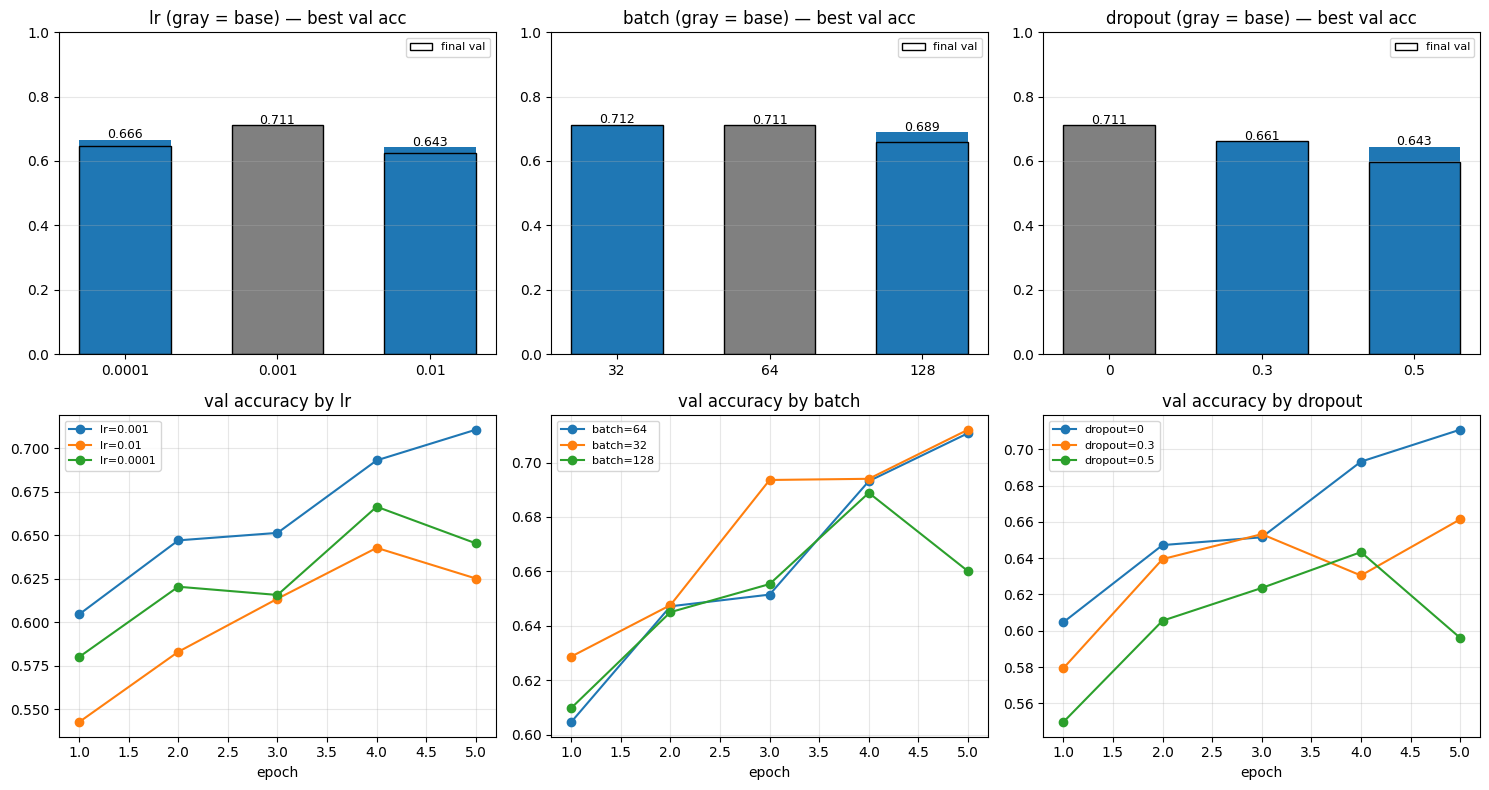

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for col, (g, names) in enumerate(groups.items()):
    key = {"① 학습률": "lr", "② 배치 크기": "batch", "③ Dropout": "dropout"}[g]
    t = table_B[table_B["항목"] == g].sort_values(key)
    labels = [f"{v:g}" for v in t[key]]
    colors = ["gray" if n == base_name else "tab:blue" for n in t["설정"]]
    ax = axes[0, col]
    ax.bar(labels, t["최고 검증"], color=colors, width=0.6)
    ax.bar(labels, t["최종 검증"], color="none", edgecolor="black", width=0.6, label="final val")
    for x_, v in zip(labels, t["최고 검증"]): ax.text(x_, v + .005, f"{v:.3f}", ha="center", fontsize=9)
    ax.set_title(f"{key} (gray = base) — best val acc"); ax.set_ylim(0, 1); ax.grid(axis="y", alpha=.3); ax.legend(fontsize=8)

    ax = axes[1, col]
    for n in [base_name] + names:
        h = results_B[n]["hist"]
        ax.plot(range(1, EPOCHS_B+1), [v[3] for v in h], marker="o", label=f"{key}={results_B[n]['cfg'][key]:g}")
    ax.set_title(f"val accuracy by {key}"); ax.set_xlabel("epoch"); ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(f"{RESULT_DIR}/04B_compare.png", dpi=150)
plt.show()


In [ ]:
print("\n" + "=" * 70)
print(" 실험 B 하이퍼파라미터 비교 (04B_table.csv)")
print("=" * 70)
tB = f"{RESULT_DIR}/04B_table.csv"
if os.path.exists(tB):
    tb = pd.read_csv(tB)
    for g, sub in tb.groupby("항목", sort=False):
        print(f"\n{g}")
        print(sub[["설정", "최종 학습", "최종 검증", "최고 검증", "차이(과적합)", "검증 손실", "시간(분)"]].to_string(index=False))
    bj = f"{RESULT_DIR}/04B_best.json"
    if os.path.exists(bj):
        print("\n★ 최적 조합:", json.load(open(bj)))
else:
    print("아직 04B_table.csv가 없습니다. 섹션 4 학습을 먼저 실행하세요.")



 실험 B 하이퍼파라미터 비교 (04B_table.csv)

① 학습률
                               설정  최종 학습  최종 검증  최고 검증  차이(과적합)  검증 손실  시간(분)
                        lr=0.0001 0.6824 0.6455 0.6665   0.0369 1.0262    4.4
기준 (lr 1e-3, batch 64, dropout 0) 0.7224 0.7108 0.7108   0.0116 0.8719    4.6
                          lr=0.01 0.6567 0.6253 0.6429   0.0315 1.1376    4.4

② 배치 크기
                               설정  최종 학습  최종 검증  최고 검증  차이(과적합)  검증 손실  시간(분)
                         batch=32 0.7088 0.7121 0.7121  -0.0032 0.8509    4.6
기준 (lr 1e-3, batch 64, dropout 0) 0.7224 0.7108 0.7108   0.0116 0.8719    4.6
                        batch=128 0.7226 0.6601 0.6889   0.0625 0.9662    4.8

③ Dropout
                               설정  최종 학습  최종 검증  최고 검증  차이(과적합)  검증 손실  시간(분)
기준 (lr 1e-3, batch 64, dropout 0) 0.7224 0.7108 0.7108   0.0116 0.8719    4.6
                      dropout=0.3 0.6335 0.6614 0.6614  -0.0278 1.0104    4.8
                      dropout=0.5 0.5908 0.5960 0.6433  -0.0053 1.1980    4.7

★ 

## 5. 실험 C — 전이학습 (사전학습 ResNet18) vs 직접 만든 CNN

10주차 수업 내용: `torchvision.models.resnet18(weights=DEFAULT)`의 마지막 `fc`를 12클래스로 교체하고,
① **freeze** — 사전학습 가중치는 고정하고 `fc`만 학습 (03) / ② **finetune** — 전체 가중치를 낮은 학습률(1e-4)로 학습 (04).
직접 만든 CNN은 실험 B의 최적 조합(`04B_best.json`)으로 다시 10 epoch 학습해 **같은 epoch·같은 데이터**에서 비교합니다.

| 모델 | 학습하는 파라미터 | lr | batch | 예상 시간 |
|---|---|---|---|---|
| 직접 CNN (실험 B 최적) | 전체 | 실험 B 최적 | 실험 B 최적 | ~10분 |
| ResNet18 freeze | `fc`만 (약 6천 개) | 1e-3 | 64 | ~8분 |
| ResNet18 finetune | 전체 (약 1,120만 개) | **1e-4** | 64 | ~15분 |

finetune의 학습률을 낮추는 이유: 이미 잘 학습된 가중치를 큰 걸음으로 흔들면 사전학습의 이점이 사라지기 때문입니다 (10주차 04).
`train_model`은 `requires_grad=False`인 파라미터를 자동으로 건너뛰므로 freeze도 같은 함수로 학습합니다.


In [37]:
from torchvision import models

# ---- 실험 B 최적 조합 불러오기 ----
best_B = json.load(open(f"{RESULT_DIR}/04B_best.json"))
best_B["batch"] = int(best_B["batch"])
print("실험 B 최적 조합:", best_B)


def make_resnet18(freeze, n_classes=NUM_CLASSES):
    """10주차: 사전학습 ResNet18 → fc 교체. freeze=True면 fc 외 가중치 고정"""
    model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    if freeze:
        for p in model.parameters():
            p.requires_grad = False
    model.fc = nn.Linear(model.fc.in_features, n_classes)   # 새 층은 항상 requires_grad=True
    return model


def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable


# 세 모델 설정 — (모델 생성 함수, lr, batch)
configs_C = {
    "직접 CNN (실험 B 최적)": dict(make=lambda: make_cnn(dropout=best_B["dropout"], batchnorm=True),
                              lr=best_B["lr"], batch=best_B["batch"]),
    "ResNet18 freeze":     dict(make=lambda: make_resnet18(freeze=True),  lr=1e-3, batch=BATCH_SIZE),
    "ResNet18 finetune":   dict(make=lambda: make_resnet18(freeze=False), lr=1e-4, batch=BATCH_SIZE),
}

# 파라미터 수 확인 (학습 전)
for name, cfg in configs_C.items():
    total, trainable = count_params(cfg["make"]())
    print(f"{name:22s} 전체 {total:>12,}  학습 대상 {trainable:>12,}")


실험 B 최적 조합: {'lr': 0.001, 'batch': 32, 'dropout': 0.0}
직접 CNN (실험 B 최적)       전체      134,540  학습 대상      134,540
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 152MB/s]


ResNet18 freeze        전체   11,182,668  학습 대상        6,156
ResNet18 finetune      전체   11,182,668  학습 대상   11,182,668


In [ ]:
results_C = {}
loaders_C = {}
def get_loader_C(batch):
    if batch not in loaders_C:
        loaders_C[batch] = make_loader(train_plain_ds, shuffle=True, batch_size=batch)
    return loaders_C[batch]

for name, cfg in configs_C.items():
    hist_path = f"{RESULT_DIR}/05C_hist_{name}.csv"
    pt_path   = f"{RESULT_DIR}/05C_{name}.pt"
    if os.path.exists(hist_path) and os.path.exists(pt_path):
        h = pd.read_csv(hist_path, index_col="epoch")
        results_C[name] = {"hist": list(h[["train_loss","train_acc","val_loss","val_acc"]].itertuples(index=False, name=None)),
                           "time": float(h["time_min"].iloc[0]) * 60, "params": tuple(h[["params_total","params_trainable"]].iloc[0])}
        print(f"▶ {name}: 저장된 결과 불러옴")
        continue

    print(f"\n▶ {name}   lr={cfg['lr']:g}, batch={cfg['batch']}")
    torch.manual_seed(SEED)
    model = cfg["make"]().to(device)
    params = count_params(model)
    hist, elapsed = train_model(model, get_loader_C(cfg["batch"]), epochs=EPOCHS, lr=cfg["lr"], tag=name)
    results_C[name] = {"hist": hist, "time": elapsed, "params": params}
    print(f"  학습 시간 {elapsed/60:.1f}분")

    df = pd.DataFrame(hist, columns=["train_loss","train_acc","val_loss","val_acc"])
    df["time_min"] = round(elapsed / 60, 2)
    df["params_total"], df["params_trainable"] = params
    df.to_csv(hist_path, index_label="epoch")
    torch.save(model.state_dict(), pt_path)          # 섹션 6·8에서 다시 불러 쓰기 위해 저장
    del model; torch.cuda.empty_cache()


▶ 직접 CNN (실험 B 최적): 저장된 결과 불러옴
▶ ResNet18 freeze: 저장된 결과 불러옴
▶ ResNet18 finetune: 저장된 결과 불러옴


### 5-1. 비교표
검증 정확도 외에 **학습 시간**과 **학습 파라미터 수**를 함께 봅니다 — 전이학습의 장점은 정확도만이 아니라 "적은 학습으로 빨리 도달"하는 데 있습니다.


In [ ]:
rows = []
for name, r in results_C.items():
    h = r["hist"]
    rows.append({"모델": name,
                 "학습 정확도": round(h[-1][1], 4), "검증 정확도": round(h[-1][3], 4),
                 "차이(과적합)": round(h[-1][1] - h[-1][3], 4),
                 "최고 검증": round(max(v[3] for v in h), 4),
                 "최고 epoch": int(max(range(len(h)), key=lambda i: h[i][3]) + 1),
                 "검증 손실": round(h[-1][2], 4),
                 "학습 파라미터": f"{int(r['params'][1]):,}",
                 "학습 시간(분)": round(r["time"] / 60, 1)})
table_C = pd.DataFrame(rows)
display(table_C)
table_C.to_csv(f"{RESULT_DIR}/05C_table.csv", index=False)

# 최종 모델 선택: 최종 검증 정확도 최고
final_name = table_C.loc[table_C["검증 정확도"].idxmax(), "모델"]
print(f"\n★ 최종 모델: {final_name}  (검증 정확도 {table_C['검증 정확도'].max():.4f})")
json.dump({"final_model": final_name}, open(f"{RESULT_DIR}/05C_final.json", "w"))

# 1 epoch만 돌렸을 때의 검증 정확도 — 전이학습의 '출발점' 이점
print("\nepoch 1 검증 정확도:", {n: round(r["hist"][0][3], 4) for n, r in results_C.items()})


,모델,학습 정확도,검증 정확도,차이(과적합),최고 검증,최고 epoch,검증 손실,학습 파라미터,학습 시간(분)
0,직접 CNN (실험 B 최적),0.7884,0.7482,0.0402,0.7482,10,0.7700,"134,540",9.1
1,ResNet18 freeze,0.9517,0.9321,0.0196,0.9351,9,0.2035,"6,156",8.4
2,ResNet18 finetune,0.9967,0.9622,0.0345,0.9682,4,0.1382,"11,182,668",10.2



★ 최종 모델: ResNet18 finetune  (검증 정확도 0.9622)

epoch 1 검증 정확도: {'직접 CNN (실험 B 최적)': 0.5948, 'ResNet18 freeze': 0.9033, 'ResNet18 finetune': 0.9519}


### 5-2. 학습 곡선
직접 CNN과 ResNet18의 곡선을 한 그림에 겹칩니다. ResNet18이 **1 epoch부터** 높은 곳에서 시작하는지, finetune이 freeze보다 얼마나 더 올라가는지 확인합니다.


/tmp/ipykernel_402/1861855037.py:14: UserWarning: Glyph 51649 (\N{HANGUL SYLLABLE JIG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_402/1861855037.py:14: UserWarning: Glyph 51217 (\N{HANGUL SYLLABLE JEOB}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_402/1861855037.py:14: UserWarning: Glyph 49892 (\N{HANGUL SYLLABLE SIL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_402/1861855037.py:14: UserWarning: Glyph 54744 (\N{HANGUL SYLLABLE HEOM}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_402/1861855037.py:14: UserWarning: Glyph 52572 (\N{HANGUL SYLLABLE COE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_402/1861855037.py:14: UserWarning: Glyph 51201 (\N{HANGUL SYLLABLE JEOG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_402/1861855037.py:15: UserWarning: Glyph 51649 (\N{HANGUL SYLLABLE JIG}) missing from font(s) DejaVu Sans.
  plt.savefig(f"{

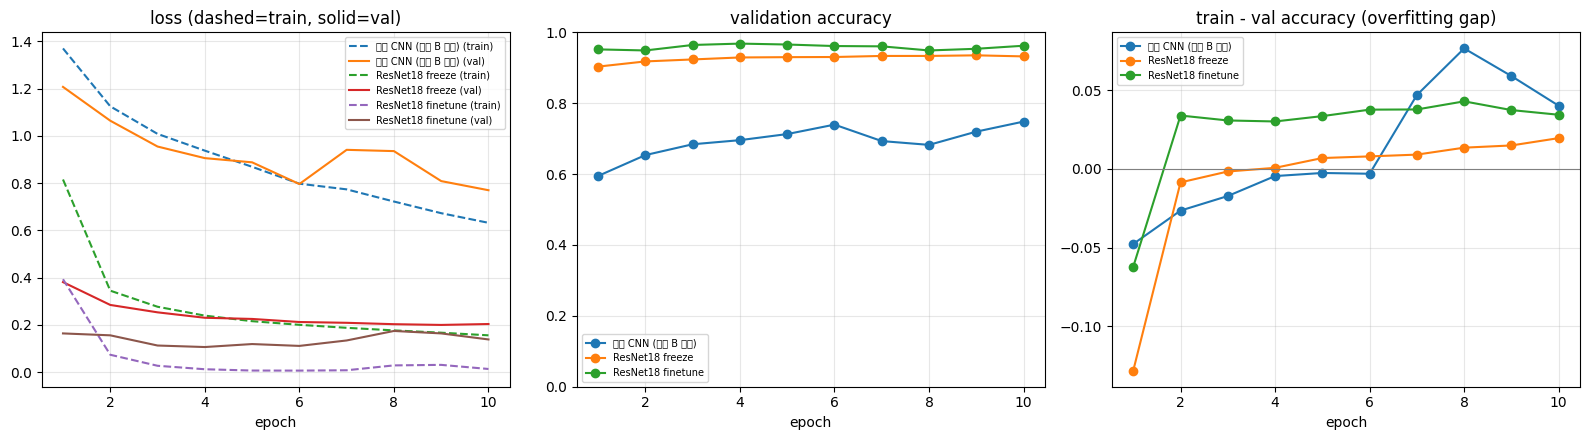

/tmp/ipykernel_402/1861855037.py:24: UserWarning: Glyph 51649 (\N{HANGUL SYLLABLE JIG}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(f"{RESULT_DIR}/05C_time_vs_acc.png", dpi=150); plt.show()
/tmp/ipykernel_402/1861855037.py:24: UserWarning: Glyph 51217 (\N{HANGUL SYLLABLE JEOB}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(f"{RESULT_DIR}/05C_time_vs_acc.png", dpi=150); plt.show()
/tmp/ipykernel_402/1861855037.py:24: UserWarning: Glyph 49892 (\N{HANGUL SYLLABLE SIL}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(f"{RESULT_DIR}/05C_time_vs_acc.png", dpi=150); plt.show()
/tmp/ipykernel_402/1861855037.py:24: UserWarning: Glyph 54744 (\N{HANGUL SYLLABLE HEOM}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(f"{RESULT_DIR}/05C_time_vs_acc.png", dpi=150); plt.show()
/tmp/ipykernel_402/1861855037.py:24: UserWarning: Glyph 52572 (\N{HANGUL SYLLABLE COE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()

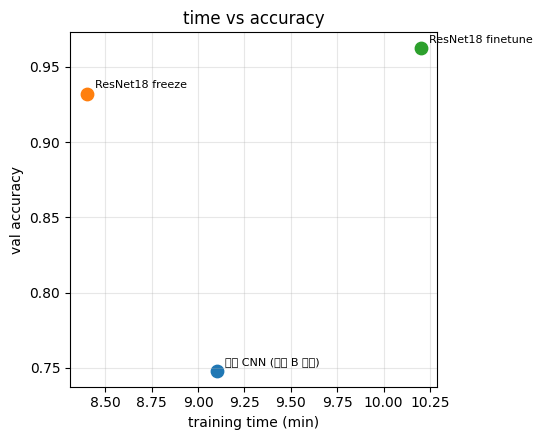

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
ep = range(1, EPOCHS + 1)
for name, r in results_C.items():
    h = r["hist"]
    axes[0].plot(ep, [v[0] for v in h], "--", label=f"{name} (train)")
    axes[0].plot(ep, [v[2] for v in h], "-",  label=f"{name} (val)")
    axes[1].plot(ep, [v[3] for v in h], marker="o", label=name)
    axes[2].plot(ep, [v[1] - v[3] for v in h], marker="o", label=name)
axes[0].set_title("loss (dashed=train, solid=val)")
axes[1].set_title("validation accuracy"); axes[1].set_ylim(0, 1)
axes[2].set_title("train - val accuracy (overfitting gap)"); axes[2].axhline(0, color="gray", lw=.8)
for ax in axes:
    ax.set_xlabel("epoch"); ax.grid(alpha=.3); ax.legend(fontsize=7)
plt.tight_layout()
plt.savefig(f"{RESULT_DIR}/05C_curves.png", dpi=150)
plt.show()

# 시간 vs 정확도 산점도 — "얼마나 빨리, 얼마나 정확하게"
plt.figure(figsize=(5.5, 4.5))
for _, row in table_C.iterrows():
    plt.scatter(row["학습 시간(분)"], row["검증 정확도"], s=80)
    plt.annotate(row["모델"], (row["학습 시간(분)"], row["검증 정확도"]), textcoords="offset points", xytext=(6, 4), fontsize=8)
plt.xlabel("training time (min)"); plt.ylabel("val accuracy"); plt.title("time vs accuracy"); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{RESULT_DIR}/05C_time_vs_acc.png", dpi=150); plt.show()


In [38]:
print("\n" + "=" * 70)
print(" 실험 C 전이학습 비교 (05C_table.csv)")
print("=" * 70)
tC = f"{RESULT_DIR}/05C_table.csv"
if os.path.exists(tC):
    print(pd.read_csv(tC).to_string(index=False))
    for f in sorted(glob.glob(f"{RESULT_DIR}/05C_hist_*.csv")):
        h = pd.read_csv(f, index_col="epoch")
        print(f"\n[{os.path.basename(f)[9:-4]}] epoch별 (학습acc / 검증acc / 차이)")
        print("  " + "  ".join(f"{i+1}:{a:.2f}/{v:.2f}/{a-v:+.2f}" for i,(a,v) in enumerate(zip(h.train_acc, h.val_acc))))
    fj = f"{RESULT_DIR}/05C_final.json"
    if os.path.exists(fj):
        print("\n★ 최종 모델:", json.load(open(fj))["final_model"])
else:
    print("아직 05C_table.csv가 없습니다. 섹션 5 학습을 먼저 실행하세요.")



 실험 C 전이학습 비교 (05C_table.csv)
               모델  학습 정확도  검증 정확도  차이(과적합)  최고 검증  최고 epoch  검증 손실    학습 파라미터  학습 시간(분)
 직접 CNN (실험 B 최적)  0.7884  0.7482   0.0402 0.7482        10 0.7700    134,540       9.1
  ResNet18 freeze  0.9517  0.9321   0.0196 0.9351         9 0.2035      6,156       8.4
ResNet18 finetune  0.9967  0.9622   0.0345 0.9682         4 0.1382 11,182,668      10.2

[ResNet18 finetune] epoch별 (학습acc / 검증acc / 차이)
  1:0.89/0.95/-0.06  2:0.98/0.95/+0.03  3:1.00/0.96/+0.03  4:1.00/0.97/+0.03  5:1.00/0.97/+0.03  6:1.00/0.96/+0.04  7:1.00/0.96/+0.04  8:0.99/0.95/+0.04  9:0.99/0.95/+0.04  10:1.00/0.96/+0.03

[ResNet18 freeze] epoch별 (학습acc / 검증acc / 차이)
  1:0.78/0.90/-0.13  2:0.91/0.92/-0.01  3:0.92/0.92/-0.00  4:0.93/0.93/+0.00  5:0.94/0.93/+0.01  6:0.94/0.93/+0.01  7:0.94/0.93/+0.01  8:0.95/0.93/+0.01  9:0.95/0.94/+0.01  10:0.95/0.93/+0.02

[직접 CNN (실험 B 최적)] epoch별 (학습acc / 검증acc / 차이)
  1:0.55/0.59/-0.05  2:0.63/0.65/-0.03  3:0.67/0.68/-0.02  4:0.69/0.70/-0.00  

## 6. 최종 평가 — 테스트셋 (딱 한 번)

지금까지 모델 선택과 하이퍼파라미터 결정에는 **검증셋**만 썼습니다. 테스트셋은 여기서 **처음이자 마지막으로** 사용합니다.
테스트셋을 보고 다시 모델을 고치면 테스트셋이 사실상 검증셋이 되어, 새 데이터에서의 성능을 부풀려 보고하게 되기 때문입니다.

1. 실험 C에서 고른 최종 모델(`05C_final.json`)을 Drive에서 불러옵니다
2. 테스트셋 전체를 **한 번만** 돌려 예측을 모아 둡니다
3. 모아 둔 예측으로 전체 정확도, 클래스별 정확도, 혼동 행렬, 틀린 이미지를 만듭니다
4. 섹션 8에서 쓸 `best_model.pt`를 저장합니다

In [39]:
#셀6-1
# 실험 C에서 고른 최종 모델 이름 읽기
final_name = json.load(open(f"{RESULT_DIR}/05C_final.json"))["final_model"]
print("최종 모델:", final_name)

# 같은 구조를 만든 뒤 저장된 가중치를 덮어씌웁니다 (10주차)
if final_name.startswith("ResNet18"):
    final_model = make_resnet18(freeze=("freeze" in final_name))
else:
    best_B = json.load(open(f"{RESULT_DIR}/04B_best.json"))
    final_model = make_cnn(dropout=best_B["dropout"], batchnorm=True)

final_model.load_state_dict(torch.load(f"{RESULT_DIR}/05C_{final_name}.pt", map_location=device))
final_model = final_model.to(device)
final_model.eval()

# 제대로 불러왔는지 확인 — 검증 정확도가 섹션 5 표의 값과 같아야 합니다
val_loss_f, val_acc_f = measure(final_model, val_loader)
print(f"검증 정확도 재확인: {val_acc_f:.4f}  (섹션 5 표의 최종 검증 정확도와 같으면 OK)")

최종 모델: ResNet18 finetune
검증 정확도 재확인: 0.9622  (섹션 5 표의 최종 검증 정확도와 같으면 OK)


In [40]:
#셀6-2
# 테스트셋을 한 번만 돌려서 정답·예측·틀린 이미지를 모두 모아 둡니다
all_true, all_pred = [], []
wrong_imgs, wrong_true, wrong_pred = [], [], []
loss_sum = 0

with torch.no_grad():
    for x, y in test_loader:
        out = final_model(x.to(device)).cpu()
        loss_sum += loss_fn(out, y).item() * y.numel()
        p = out.argmax(dim=1)
        all_true.append(y); all_pred.append(p)

        wrong = p != y
        if wrong.any() and sum(len(t) for t in wrong_true) < 16:   # 틀린 이미지는 16장까지만
            wrong_imgs.append(x[wrong]); wrong_true.append(y[wrong]); wrong_pred.append(p[wrong])

all_true = torch.cat(all_true)
all_pred = torch.cat(all_pred)

test_acc  = (all_true == all_pred).float().mean().item()
test_loss = loss_sum / len(all_true)

print("=" * 50)
print(f" 최종 모델: {final_name}")
print(f" 테스트 이미지 수: {len(all_true)}장")
print(f" 테스트 정확도: {test_acc:.4f}   (맞힘 {(all_true == all_pred).sum().item()}장)")
print(f" 테스트 손실:   {test_loss:.4f}")
print(f" 검증 정확도:   {val_acc_f:.4f}   → 차이 {val_acc_f - test_acc:+.4f}")
print("=" * 50)

json.dump({"final_model": final_name, "test_acc": round(test_acc, 4), "test_loss": round(test_loss, 4),
           "val_acc": round(val_acc_f, 4), "n_test": len(all_true)},
          open(f"{RESULT_DIR}/06_test_result.json", "w"), ensure_ascii=False)

 최종 모델: ResNet18 finetune
 테스트 이미지 수: 2328장
 테스트 정확도: 0.9695   (맞힘 2257장)
 테스트 손실:   0.1243
 검증 정확도:   0.9622   → 차이 -0.0073


,클래스,테스트 장수,맞힘,정확도
0,plastic,120,106,0.8833
1,metal,110,100,0.9091
2,white-glass,104,98,0.9423
3,cardboard,121,115,0.9504
4,paper,160,153,0.9563
5,battery,166,160,0.9639
6,trash,109,106,0.9725
7,biological,125,122,0.9760
8,clothes,794,780,0.9824
9,brown-glass,95,94,0.9895


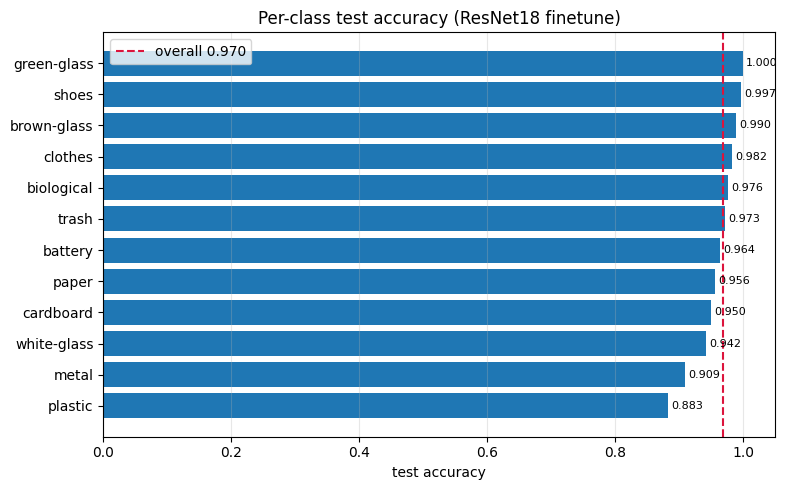

In [41]:
#셀 6-3
rows = []
for c in range(NUM_CLASSES):
    mask = all_true == c
    n_c = mask.sum().item()
    correct_c = (all_pred[mask] == c).sum().item()
    rows.append({"클래스": class_names[c], "테스트 장수": n_c, "맞힘": correct_c,
                 "정확도": round(correct_c / n_c, 4)})

per_class_df = pd.DataFrame(rows).sort_values("정확도").reset_index(drop=True)
display(per_class_df)
per_class_df.to_csv(f"{RESULT_DIR}/06_per_class.csv", index=False)

# 가로 막대 — 아래쪽일수록 어려운 클래스
plt.figure(figsize=(8, 5))
plt.barh(per_class_df["클래스"], per_class_df["정확도"], color="tab:blue")
plt.axvline(test_acc, color="crimson", ls="--", label=f"overall {test_acc:.3f}")
for i, v in enumerate(per_class_df["정확도"]):
    plt.text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=8)
plt.xlim(0, 1.05); plt.xlabel("test accuracy")
plt.title(f"Per-class test accuracy ({final_name})")
plt.legend(); plt.grid(axis="x", alpha=.3)
plt.tight_layout()
plt.savefig(f"{RESULT_DIR}/06_per_class.png", dpi=150)
plt.show()

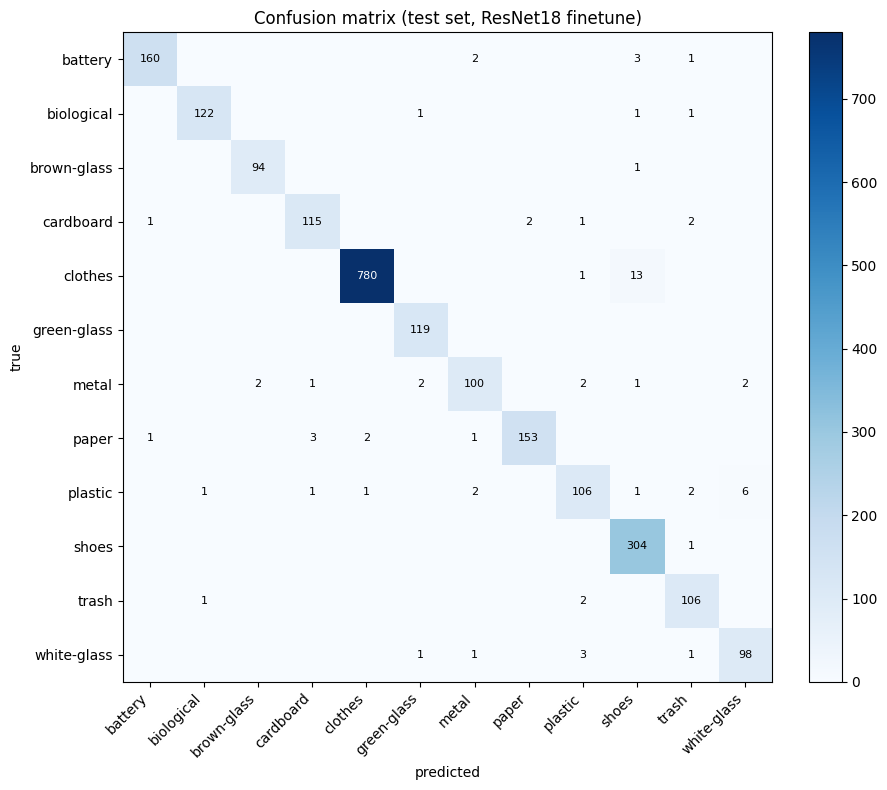

가장 많이 헷갈린 조합 (정답 → 예측)


,정답,예측,개수
0,clothes,shoes,13
1,plastic,white-glass,6
2,white-glass,plastic,3
3,paper,cardboard,3
4,battery,shoes,3


In [42]:
#셀 6-4
# 혼동 행렬: 행 = 정답, 열 = 예측. 대각선이 맞힌 개수
cm = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.int64)
for t, p in zip(all_true, all_pred):
    cm[t, p] += 1

cm_df = pd.DataFrame(cm.numpy(), index=class_names, columns=class_names)
cm_df.to_csv(f"{RESULT_DIR}/06_confusion.csv")

plt.figure(figsize=(9, 8))
plt.imshow(cm.numpy(), cmap="Blues")
plt.colorbar(fraction=0.046)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        v = cm[i, j].item()
        if v > 0:
            plt.text(j, i, v, ha="center", va="center", fontsize=8,
                     color="white" if v > cm.max().item() / 2 else "black")
plt.xticks(range(NUM_CLASSES), class_names, rotation=45, ha="right")
plt.yticks(range(NUM_CLASSES), class_names)
plt.xlabel("predicted"); plt.ylabel("true")
plt.title(f"Confusion matrix (test set, {final_name})")
plt.tight_layout()
plt.savefig(f"{RESULT_DIR}/06_confusion.png", dpi=150)
plt.show()

# 가장 많이 헷갈린 조합 상위 5개 (대각선 제외)
pairs = []
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        if i != j and cm[i, j] > 0:
            pairs.append({"정답": class_names[i], "예측": class_names[j], "개수": cm[i, j].item()})
top_conf = pd.DataFrame(pairs).sort_values("개수", ascending=False).head(5).reset_index(drop=True)
print("가장 많이 헷갈린 조합 (정답 → 예측)")
display(top_conf)
top_conf.to_csv(f"{RESULT_DIR}/06_top_confusions.csv", index=False)

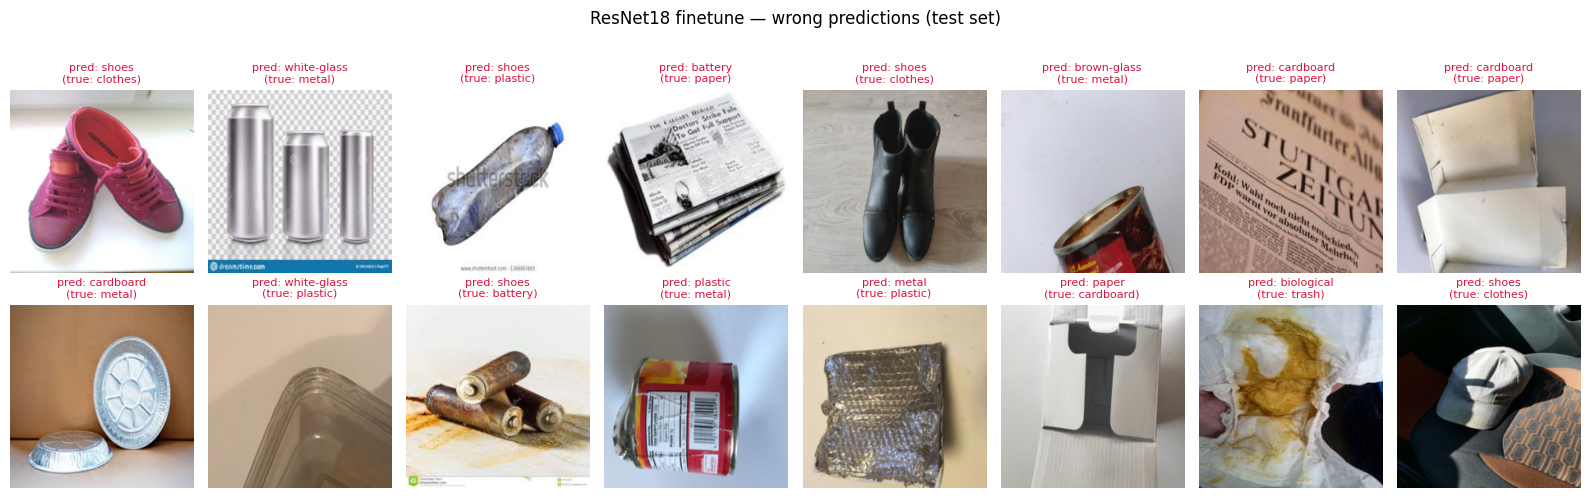

In [43]:
#셀6-5
imgs  = torch.cat(wrong_imgs)[:16]
trues = torch.cat(wrong_true)[:16]
preds = torch.cat(wrong_pred)[:16]

fig, axes = plt.subplots(2, 8, figsize=(16, 5))
for ax_, i in zip(axes.flatten(), range(16)):
    ax_.axis("off")
    if i < len(imgs):
        ax_.imshow(denorm(imgs[i]))
        ax_.set_title(f"pred: {class_names[preds[i]]}\n(true: {class_names[trues[i]]})",
                      fontsize=8, color="crimson")
plt.suptitle(f"{final_name} — wrong predictions (test set)", y=1.02)
plt.tight_layout()
plt.savefig(f"{RESULT_DIR}/06_wrong.png", dpi=150)
plt.show()

In [44]:
#셀6-6
# 섹션 8(새 이미지 예측)에서 불러 쓸 최종 모델 + 정보 /
torch.save(final_model.state_dict(), f"{RESULT_DIR}/best_model.pt")
json.dump({"model": final_name, "class_names": class_names, "img_size": IMG_SIZE,
           "mean": MEAN, "std": STD, "test_acc": round(test_acc, 4)},
          open(f"{RESULT_DIR}/best_model_info.json", "w"), ensure_ascii=False, indent=2)
print("저장:", f"{RESULT_DIR}/best_model.pt")
print("저장:", f"{RESULT_DIR}/best_model_info.json")

저장: /content/drive/MyDrive/garbage_hackathon/results/best_model.pt
저장: /content/drive/MyDrive/garbage_hackathon/results/best_model_info.json


## 7. 결론

### 실험 요약
| 실험 | 비교 내용 | 핵심 결과 |
|---|---|---|
| A | 기본 / Dropout / BatchNorm / 증강 CNN (10 epoch) | BatchNorm CNN이 검증 정확도 0.733로 가장 높음 |
| 3-5 | BatchNorm 20ep vs BatchNorm+Dropout0.3+증강 20ep | 규제 없는 모델은 10 epoch 이후 과적합 (학습−검증 차이 +0.049 → +0.132, 검증 손실 0.78 → 0.87 상승). 조합 모델은 차이 +0.022 유지 |
| B | 학습률 / 배치 크기 / Dropout (5 epoch) | lr 1e-3, batch 32, dropout 0 |
| C | 직접 CNN vs ResNet18 freeze vs finetune (10 epoch) | finetune 검증 0.962, 1 epoch부터 0.95 |
| 최종 | ResNet18 finetune, 테스트셋 1회 평가 | **테스트 정확도 0.9695** (2,257 / 2,328) |

### 최종 모델로 ResNet18 finetune을 고른 이유
1. 세 모델 중 검증 정확도가 가장 높았다 (0.9622, 직접 CNN보다 0.214 높음).
2. 테스트 정확도 0.9695로 검증과의 차이가 0.0073에 불과해, 검증셋으로 고른 모델이 처음 보는 데이터에서도 같은 수준으로 동작했다.
3. 학습 시간(10.3분)은 직접 CNN(9.1분)과 비슷했지만, 사전학습 가중치 덕분에 1 epoch부터 0.95에 도달했다.
4. 학습 정확도가 1.00에 도달하고 검증 최고점이 epoch 4였다는 점에서 약한 과적합은 있지만, 검증 정확도는 0.95~0.97 범위에서 안정적으로 유지되었다.

### 한계
- plastic(0.883)과 metal(0.909)의 정확도가 가장 낮고, plastic과 white-glass를 서로 9건 헷갈렸다.
- 클래스 불균형(clothes가 다른 클래스보다 훨씬 많음)을 따로 보정하지 않았다.
- 모든 실험을 시드 하나로 한 번씩만 돌렸다. GPU 비결정성 때문에 같은 설정에서도 ±2% 정도 결과가 달라질 수 있다.
- 시간 제약으로 epoch을 5~20 사이로 제한했다.


## 8. 새 이미지 예측

섹션 6에서 저장한 최종 모델(`best_model.pt`)을 불러와, 데이터셋에 없는 새 사진이 어떤 쓰레기인지 예측합니다.
검증·테스트와 **똑같은 변환(`eval_tf`)**을 적용해야 학습 때와 같은 조건이 됩니다.

1. `best_model.pt`와 `best_model_info.json`을 불러옵니다
2. `predict()` 함수: 이미지 → `eval_tf` → `unsqueeze(0)`로 배치 차원 추가 → 모델 → `softmax`로 확률 변환 → 상위 3개
3. 직접 찍은 사진이나 인터넷 이미지를 넣어 결과를 확인합니다

In [45]:
info = json.load(open(f"{RESULT_DIR}/best_model_info.json"))
class_names = info["class_names"]
print("모델:", info["model"], "| 테스트 정확도:", info["test_acc"])

# 같은 구조를 만들고 저장된 가중치를 덮어씌웁니다 (섹션 6-1과 같은 방식)
if info["model"].startswith("ResNet18"):
    best_model = make_resnet18(freeze=("freeze" in info["model"]))
else:
    best_B = json.load(open(f"{RESULT_DIR}/04B_best.json"))
    best_model = make_cnn(dropout=best_B["dropout"], batchnorm=True)

best_model.load_state_dict(torch.load(f"{RESULT_DIR}/best_model.pt", map_location=device))
best_model = best_model.to(device)
best_model.eval()
print("불러오기 완료")

모델: ResNet18 finetune | 테스트 정확도: 0.9695
불러오기 완료


In [46]:
from PIL import Image

def predict(img, top_k=3, show=True, save=None):
    """img: 파일 경로 또는 PIL 이미지. 상위 top_k개 (클래스, 확률)을 돌려줍니다."""
    if isinstance(img, str):
        img = Image.open(img)
    img = img.convert("RGB")                        # png 투명 배경·흑백 사진도 3채널로 통일

    x = eval_tf(img).unsqueeze(0).to(device)        # (3, 224, 224) → (1, 3, 224, 224)
    with torch.no_grad():
        prob = torch.softmax(best_model(x), dim=1)[0].cpu()   # 점수 → 확률 (합이 1)

    top_p, top_i = prob.topk(top_k)
    result = [(class_names[i], round(p.item(), 4)) for p, i in zip(top_p, top_i)]

    if show:
        fig, ax = plt.subplots(1, 2, figsize=(9, 3.5), gridspec_kw={"width_ratios": [1, 1.2]})
        ax[0].imshow(img); ax[0].axis("off")
        ax[0].set_title(f"pred: {result[0][0]} ({result[0][1]:.1%})")
        ax[1].barh([r[0] for r in result][::-1], [r[1] for r in result][::-1])
        ax[1].set_xlim(0, 1); ax[1].set_xlabel("probability"); ax[1].set_title(f"top {top_k}")
        ax[1].grid(axis="x", alpha=.3)
        plt.tight_layout()
        if save:
            plt.savefig(save, dpi=150)
        plt.show()
    return result

Saving 1234234.jpg to 1234234.jpg
Saving 4123412351235234.jpg to 4123412351235234.jpg
Saving whd.png to whd.png

▶ 1234234.jpg


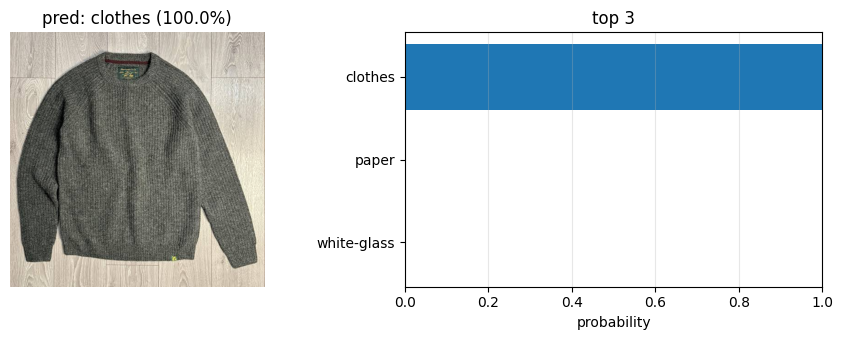

  1위  clothes      100.0%
  2위  paper        0.0%
  3위  white-glass  0.0%

▶ 4123412351235234.jpg


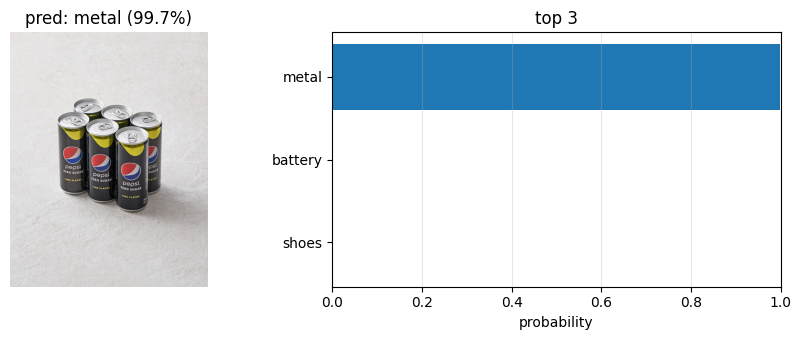

  1위  metal        99.7%
  2위  battery      0.3%
  3위  shoes        0.0%

▶ whd.png


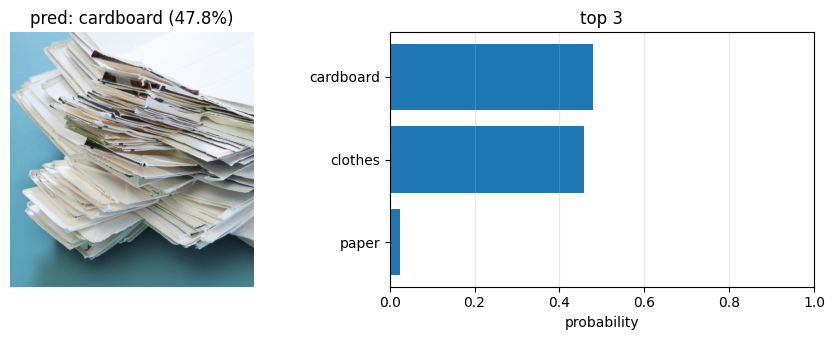

  1위  cardboard    47.8%
  2위  clothes      45.9%
  3위  paper        2.4%


,파일,1위,1위 확률,2위,2위 확률,3위,3위 확률
0,1080125_A1.webp,white-glass,0.9656,metal,0.0179,plastic,0.0116
1,f446e70a695a4457b76d70ccd6cb4271.jpg,metal,0.4557,cardboard,0.2998,trash,0.2145
2,images.jpg,cardboard,0.9485,paper,0.0298,clothes,0.0163
3,1080125_A1 (1).webp,white-glass,0.9656,metal,0.0179,plastic,0.0116
4,b7850fbd-e116-4447-ad9d-25db04c343f7 (1).webp,green-glass,1.0000,brown-glass,0.0000,metal,0.0000
5,f446e70a695a4457b76d70ccd6cb4271 (1).jpg,metal,0.4557,cardboard,0.2998,trash,0.2145
6,images (1).jpg,cardboard,0.9485,paper,0.0298,clothes,0.0163
7,1234234.jpg,clothes,0.9999,paper,0.0000,white-glass,0.0000
8,4123412351235234.jpg,metal,0.9973,battery,0.0026,shoes,0.0000
9,whd.png,cardboard,0.4780,clothes,0.4589,paper,0.0237


In [47]:
from google.colab import files

uploaded = files.upload()     # "파일 선택" 버튼이 나오면 사진을 고르세요 (여러 장 한꺼번에 가능)

rows = []
for fname in uploaded:
    print(f"\n▶ {fname}")
    stem = os.path.splitext(fname)[0]                       # 확장자 뺀 파일 이름
    res = predict(fname, save=f"{RESULT_DIR}/08_pred_{stem}.png")   # 파일 이름별로 따로 저장
    for rank, (c, p) in enumerate(res, 1):
        print(f"  {rank}위  {c:12s} {p:.1%}")
    rows.append({"파일": fname, "1위": res[0][0], "1위 확률": res[0][1],
                 "2위": res[1][0], "2위 확률": res[1][1], "3위": res[2][0], "3위 확률": res[2][1]})

# 이전 결과에 이어 붙이기 (덮어쓰지 않음)
pred_df = pd.DataFrame(rows)
csv_path = f"{RESULT_DIR}/08_predictions.csv"
if os.path.exists(csv_path):
    pred_df = pd.concat([pd.read_csv(csv_path), pred_df], ignore_index=True)
pred_df.to_csv(csv_path, index=False)
display(pred_df)